In [ ]:

# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Machine learning libraries
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor
)

from sklearn.dummy import DummyClassifier

import os
import joblib

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Cell 2: Load datasets

train = pd.read_csv("dataset_C_training.csv")
test = pd.read_csv("dataset_C_testing.csv")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

display(train.head())
display(test.head())


Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


In [ ]:

# Cell 3: Basic information

print("TRAINING DATA INFORMATION")
print("=" * 50)

train.info()

print("\nTESTING DATA INFORMATION")
print("=" * 50)

test.info()


TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance      

In [ ]:

# Cell 4: Statistical summary

display(train.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0


In [ ]:

# Cell 5: Column names and data types

column_info = pd.DataFrame({
    "Column": train.columns,
    "Data_Type": train.dtypes.astype(str).values,
    "Missing_Values": train.isnull().sum().values,
    "Missing_Percentage": (
        train.isnull().mean().values * 100
    )
})

display(column_info)


,Column,Data_Type,Missing_Values,Missing_Percentage
0,respondent_id,int64,0,0.000000
1,covid_concern,float64,12,0.252313
2,covid_knowledge,float64,27,0.567704
3,behavioral_antiviral_meds,float64,14,0.294365
4,behavioral_avoidance,float64,27,0.567704
5,behavioral_face_mask,float64,2,0.042052
6,behavioral_wash_hands,float64,9,0.189235
7,behavioral_large_gatherings,float64,10,0.210261
8,behavioral_outside_home,float64,14,0.294365
9,behavioral_touch_face,float64,21,0.441548


In [ ]:

# Cell 6: Missing value analysis

missing = train.isnull().sum().sort_values(
    ascending=False
)

missing_percentage = (
    train.isnull().mean() * 100
).sort_values(ascending=False)

missing_table = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_percentage
})

display(missing_table[missing_table["Missing_Count"] > 0])


,Missing_Count,Missing_Percentage
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


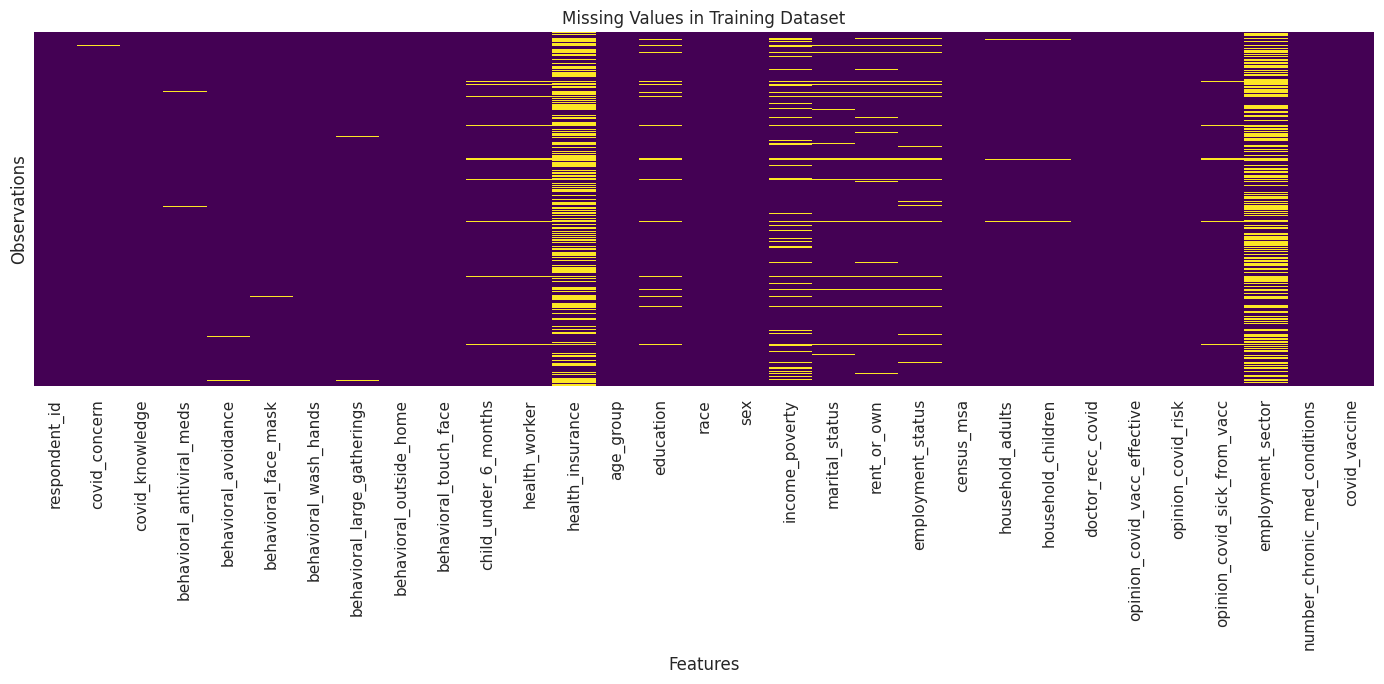

In [ ]:

# Cell 7: Missing value visualisation

plt.figure(figsize=(14, 7))

sns.heatmap(
    train.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Training Dataset")
plt.xlabel("Features")
plt.ylabel("Observations")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [ ]:

# Cell 8: Duplicate analysis

print("Duplicate rows:", train.duplicated().sum())

print(
    "Duplicate respondent IDs:",
    train["respondent_id"].duplicated().sum()
)

print(
    "Unique respondent IDs:",
    train["respondent_id"].nunique()
)


Duplicate rows: 0
Duplicate respondent IDs: 0
Unique respondent IDs: 4756


In [ ]:

# Cell 9: Categorical variable exploration

categorical_columns = train.select_dtypes(
    include=["object"]
).columns.tolist()

for col in categorical_columns:
    print("\nFeature:", col)
    print(train[col].value_counts(dropna=False))



Feature: age_group
age_group
65+ Years        1208
55 - 64 Years     992
45 - 54 Years     948
18 - 34 Years     947
35 - 44 Years     661
Name: count, dtype: int64

Feature: education
education
College Graduate    1883
Some College        1222
12 Years            1018
< 12 Years           405
NaN                  228
Name: count, dtype: int64

Feature: race
race
White                3798
Black                 353
Hispanic              321
Other or Multiple     284
Name: count, dtype: int64

Feature: sex
sex
Female    2865
Male      1891
Name: count, dtype: int64

Feature: income_poverty
income_poverty
<= $75,000, Above Poverty    2255
> $75,000                    1295
NaN                           748
Below Poverty                 458
Name: count, dtype: int64

Feature: marital_status
marital_status
Married        2464
Not Married    2061
NaN             231
Name: count, dtype: int64

Feature: rent_or_own
rent_or_own
Own     3393
Rent    1034
NaN      329
Name: count, dtype: int64

F

covid_vaccine
0    3202
1    1554
Name: count, dtype: int64

Target percentages:
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


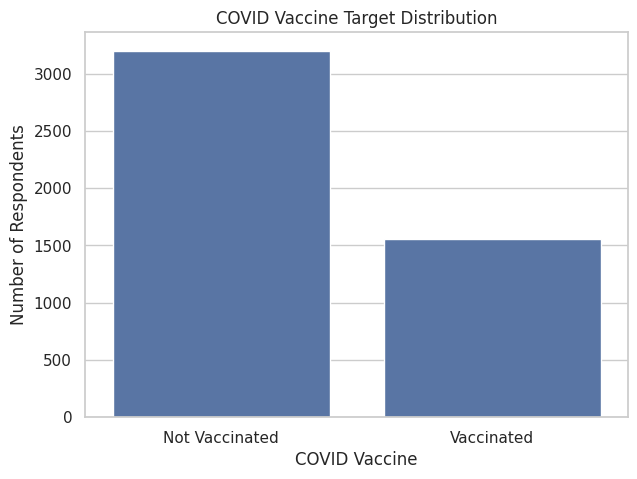

In [ ]:

# Cell 10: Target variable distribution

print(train["covid_vaccine"].value_counts())

print("\nTarget percentages:")
print(
    train["covid_vaccine"].value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x="covid_vaccine"
)

plt.title("COVID Vaccine Target Distribution")
plt.xlabel("COVID Vaccine")
plt.ylabel("Number of Respondents")
plt.xticks([0, 1], ["Not Vaccinated", "Vaccinated"])

plt.show()


In [ ]:

# Cell 11: Identify numerical and categorical columns

numerical_columns = train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove identifier and target
numerical_columns = [
    col for col in numerical_columns
    if col not in ["respondent_id", "covid_vaccine"]
]

categorical_columns = train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)


Numerical columns:
['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

Categorical columns:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


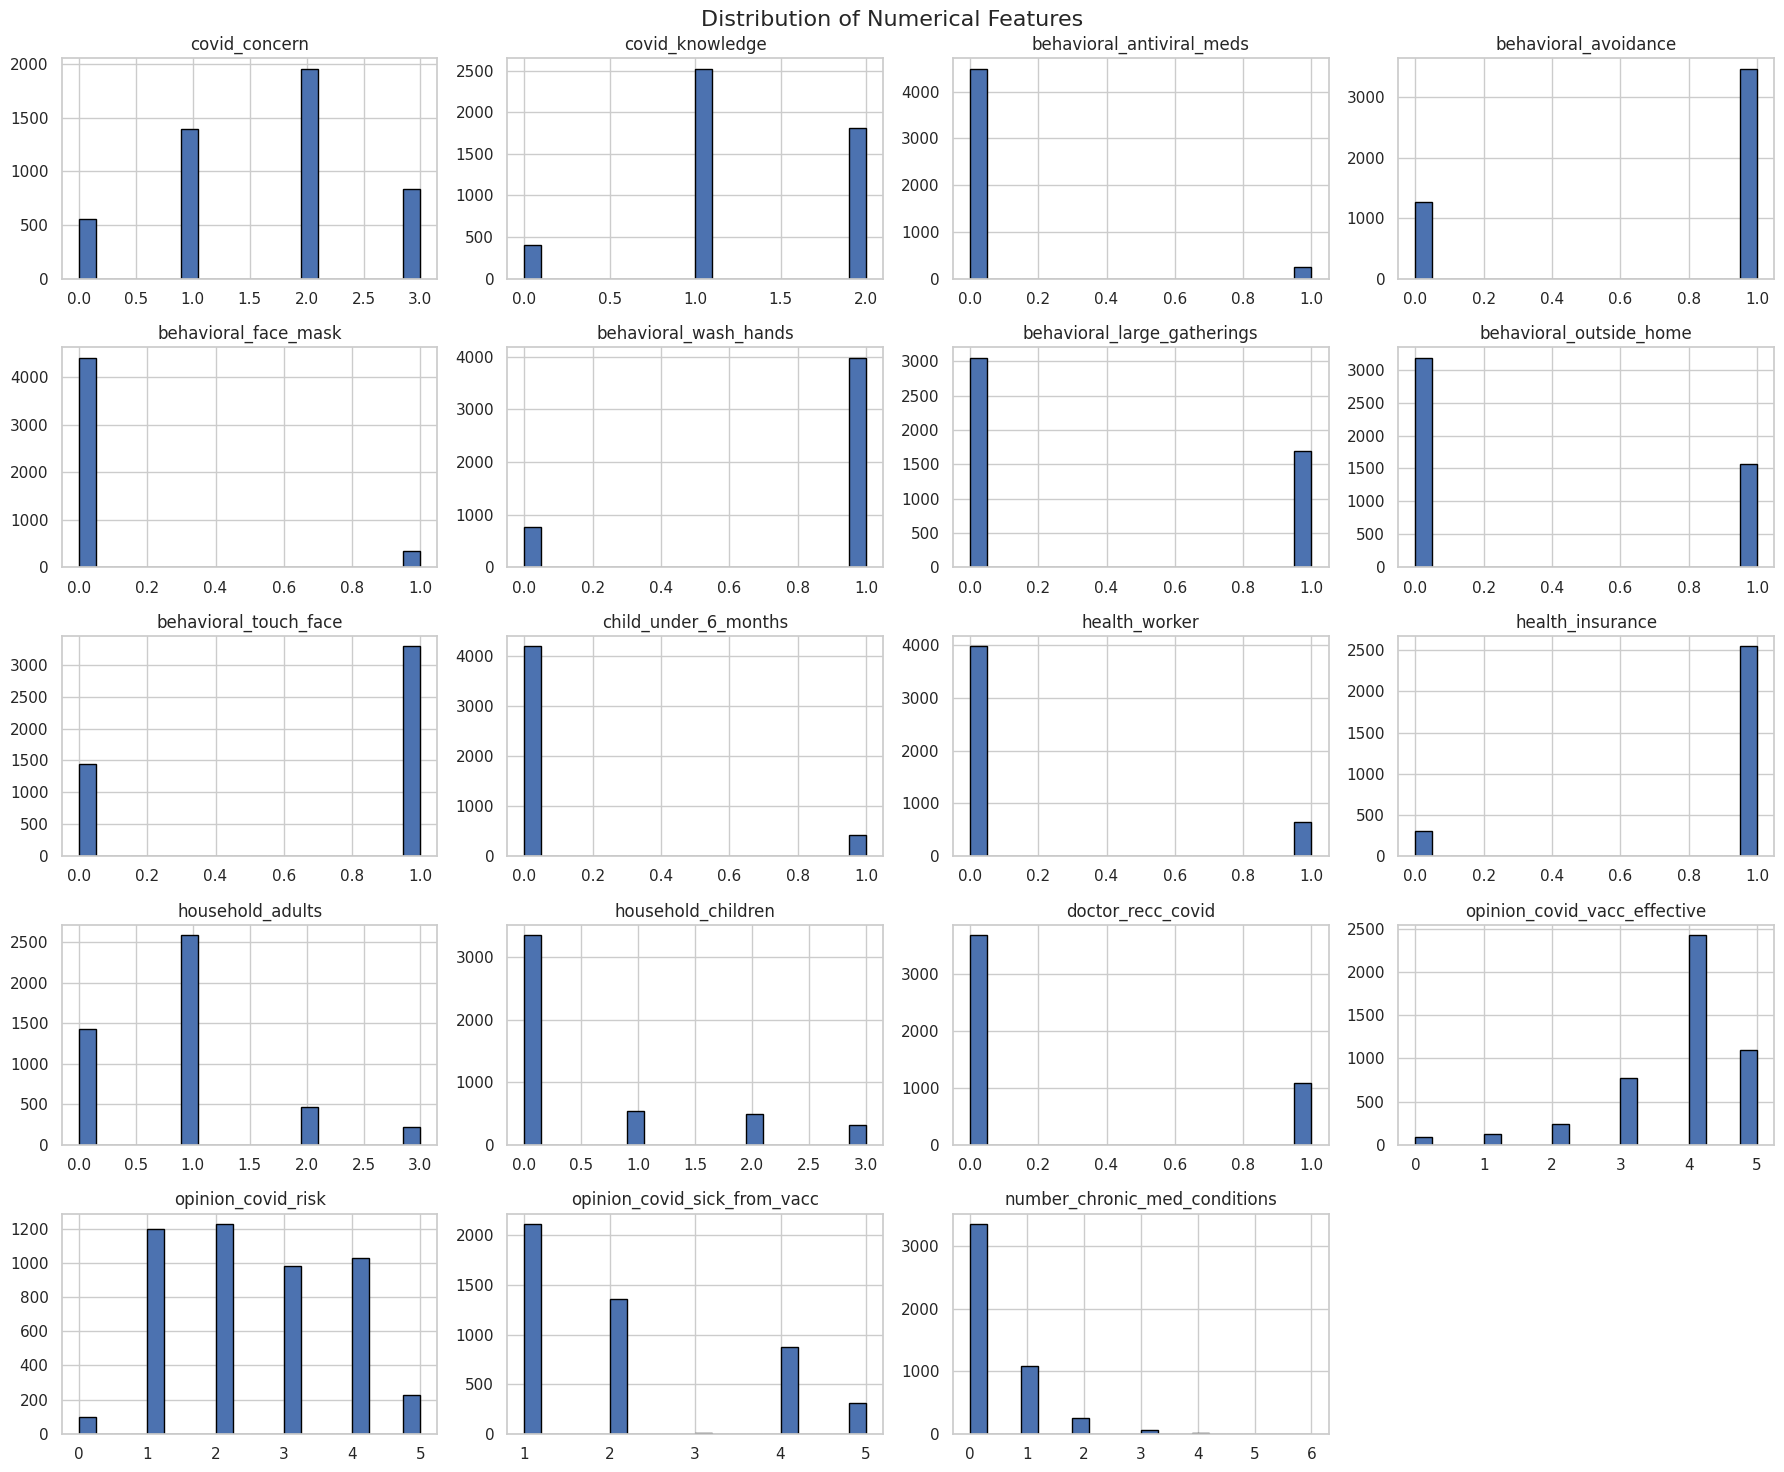

In [ ]:

# Cell 12: Distribution plots for numerical variables

train[numerical_columns].hist(
    figsize=(18, 15),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


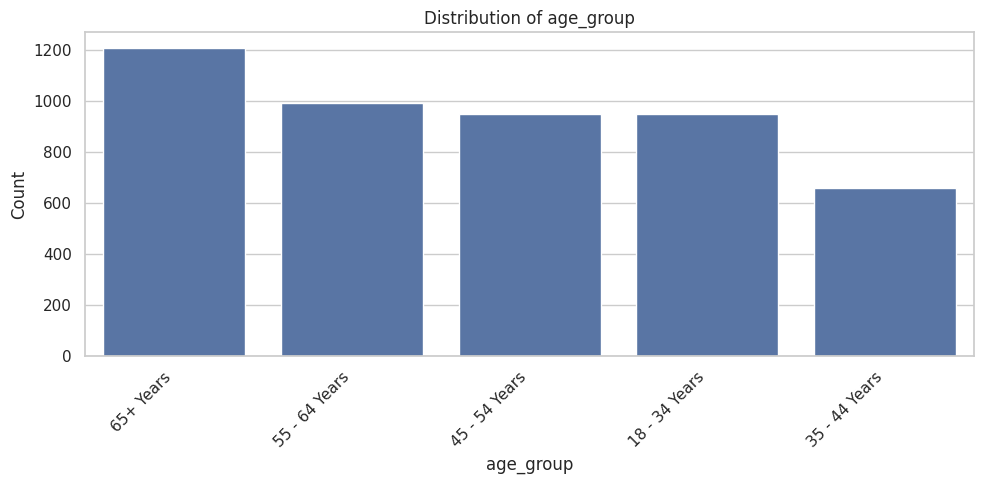

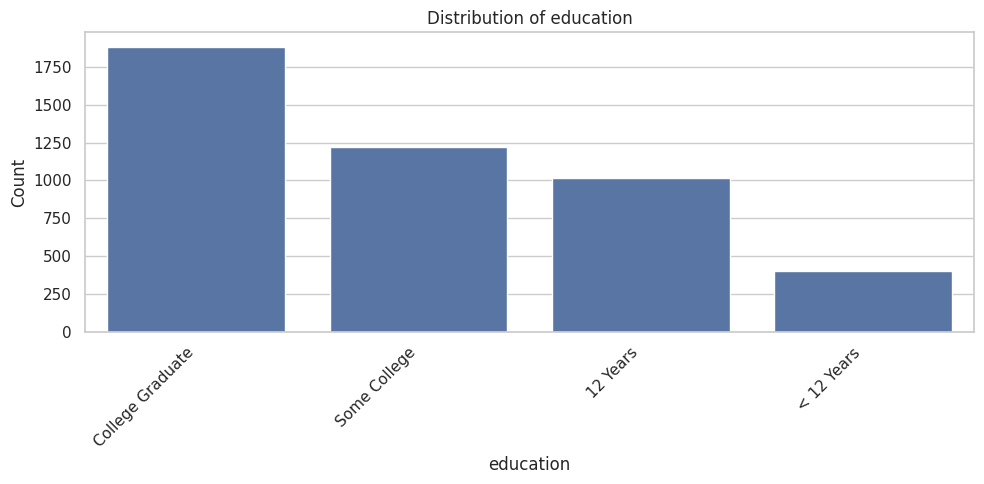

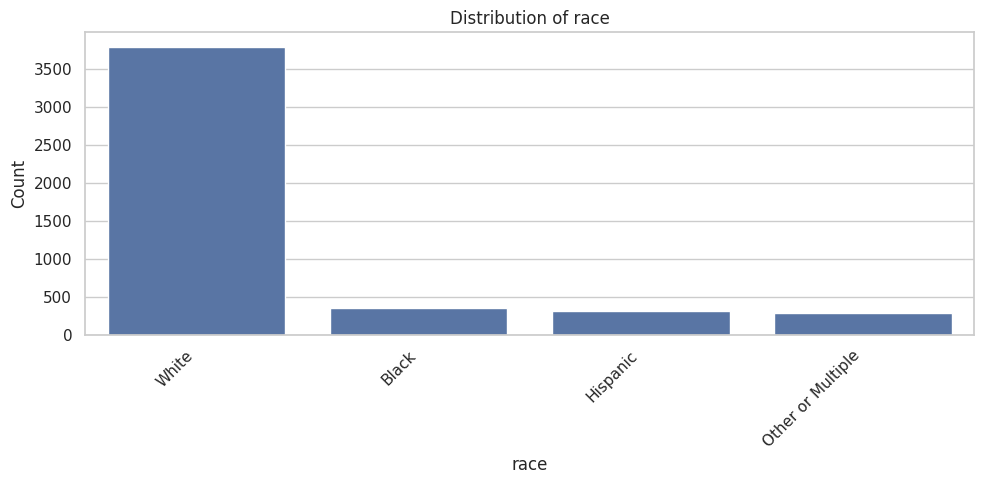

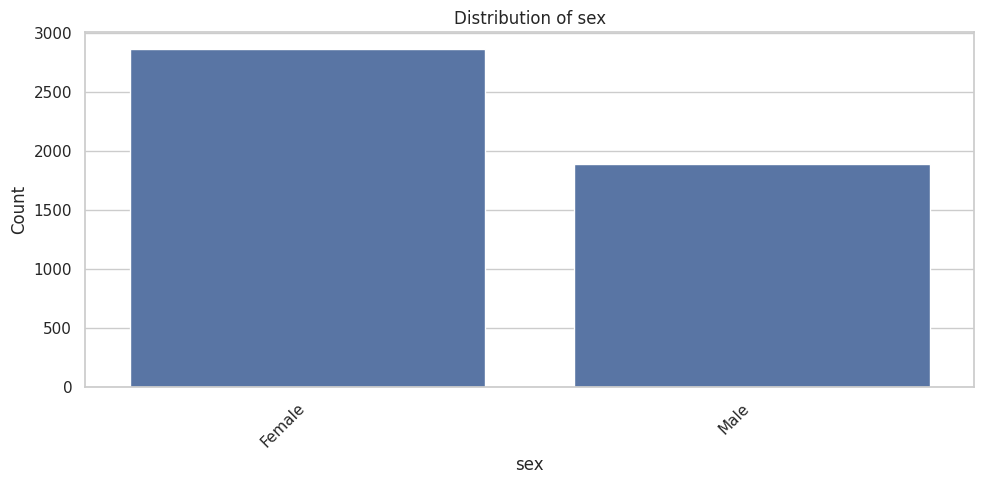

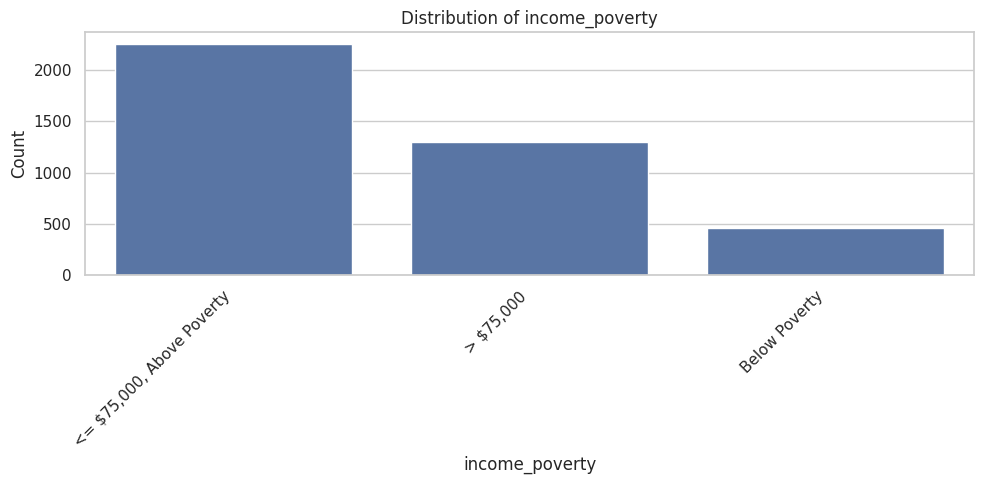

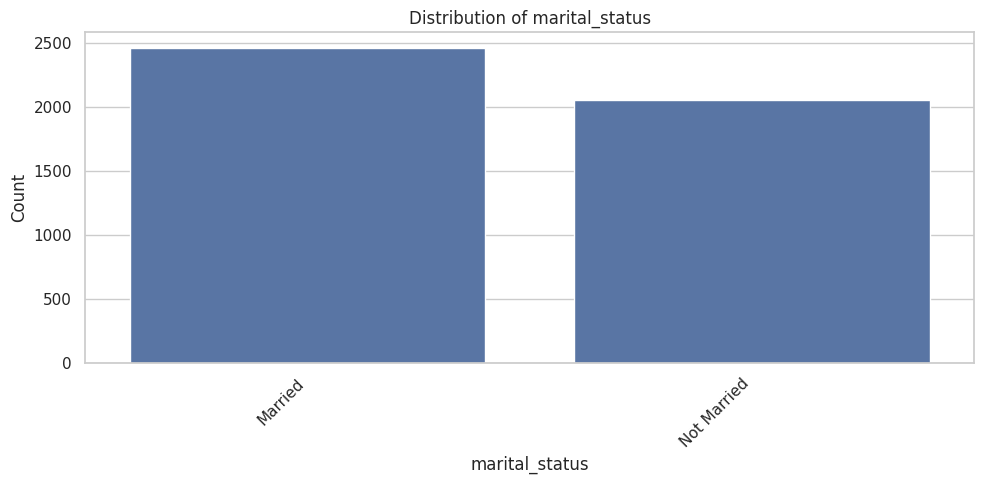

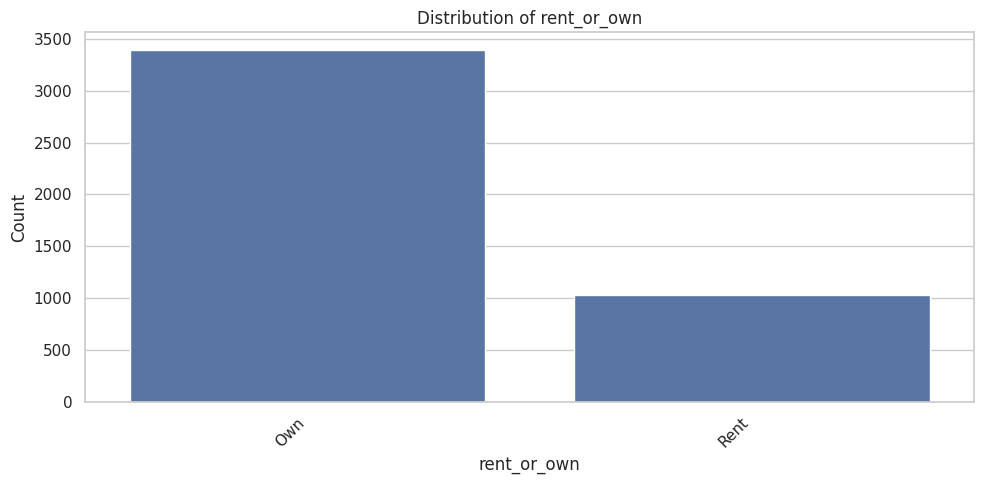

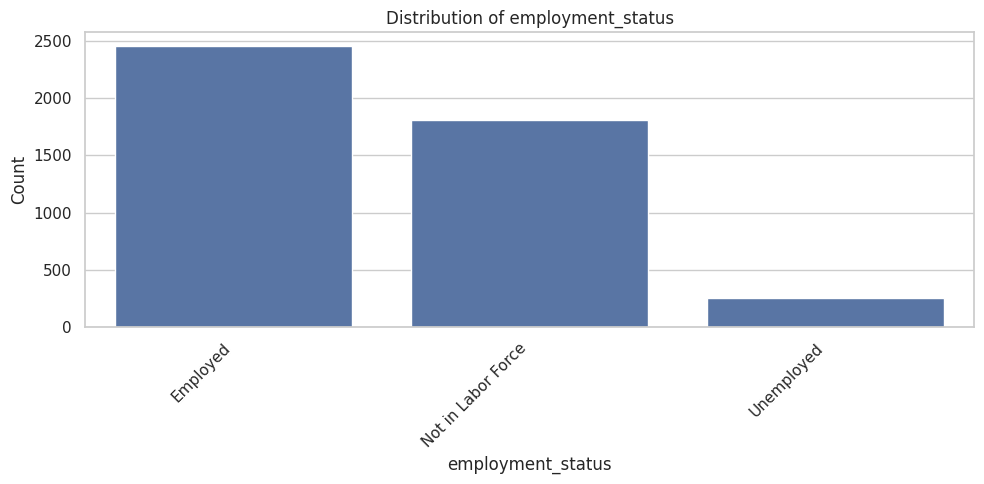

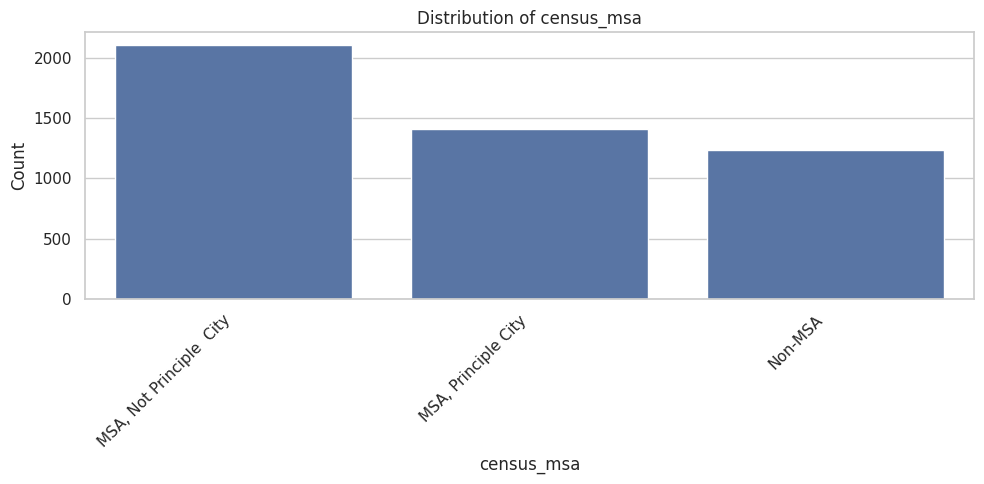

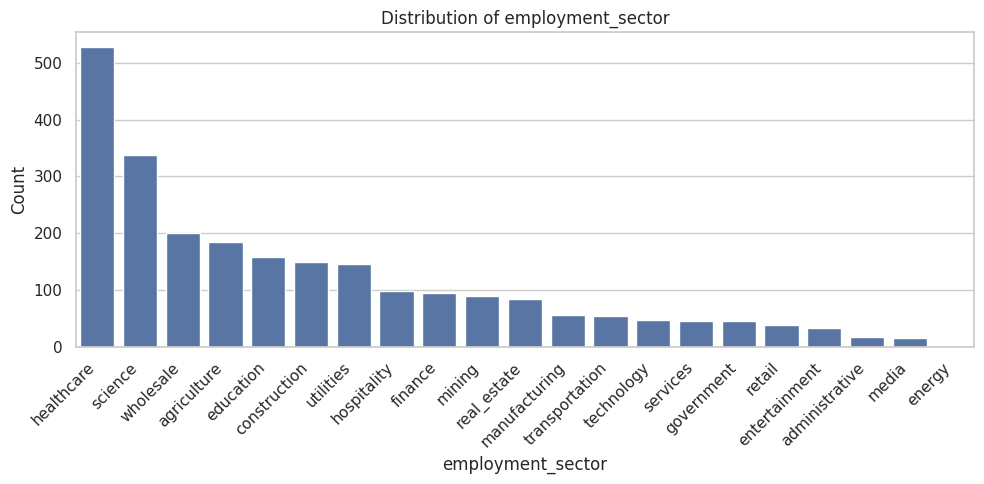

In [ ]:

# Cell 13: Categorical feature distributions

for col in categorical_columns:

    plt.figure(figsize=(10, 5))

    order = train[col].value_counts().index

    sns.countplot(
        data=train,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()


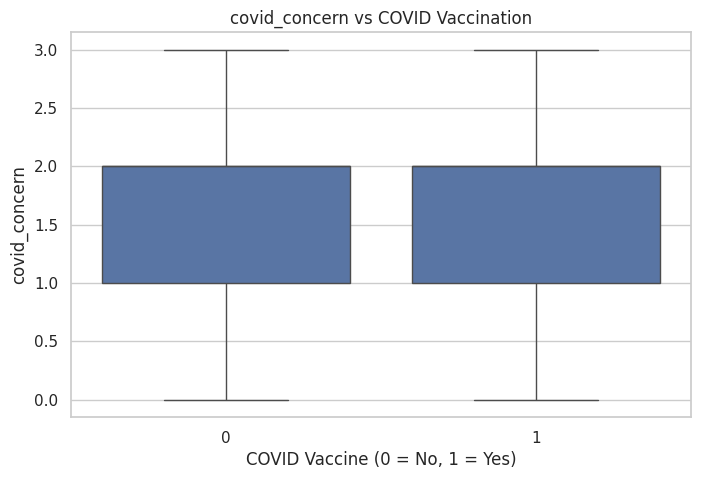

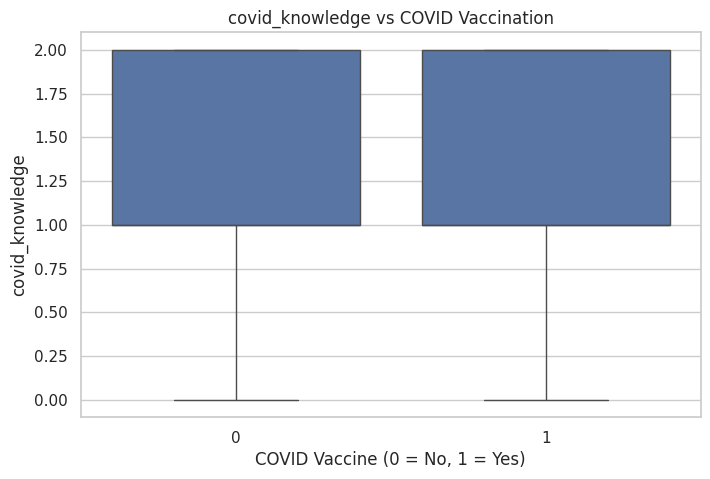

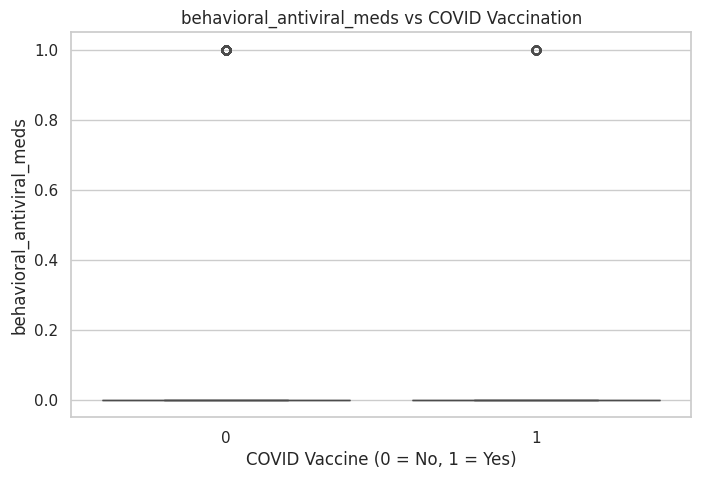

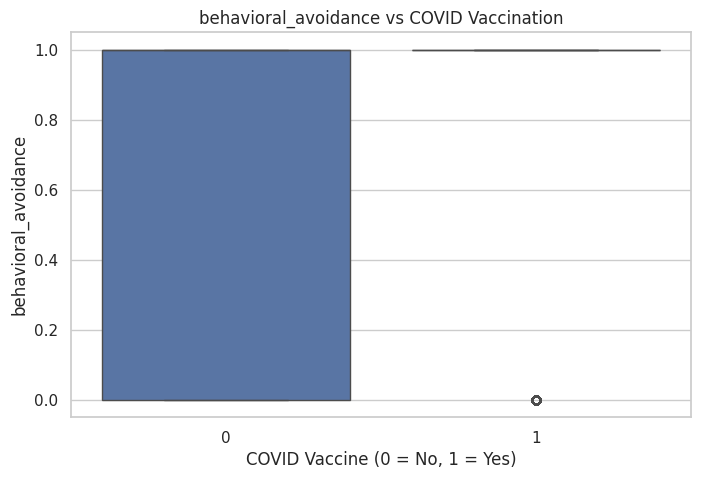

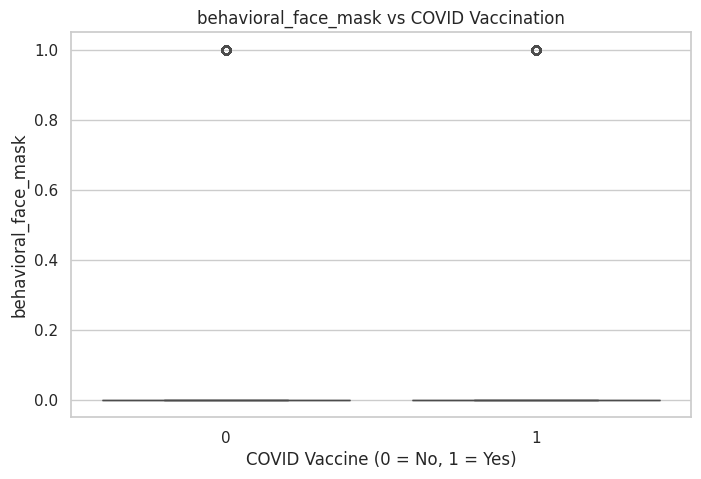

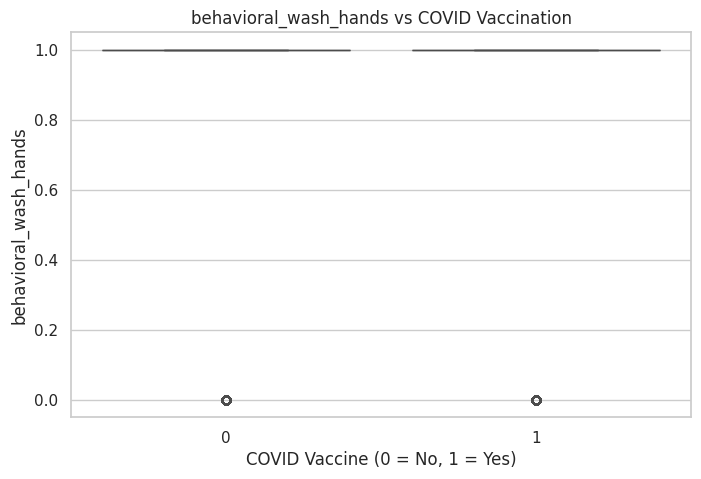

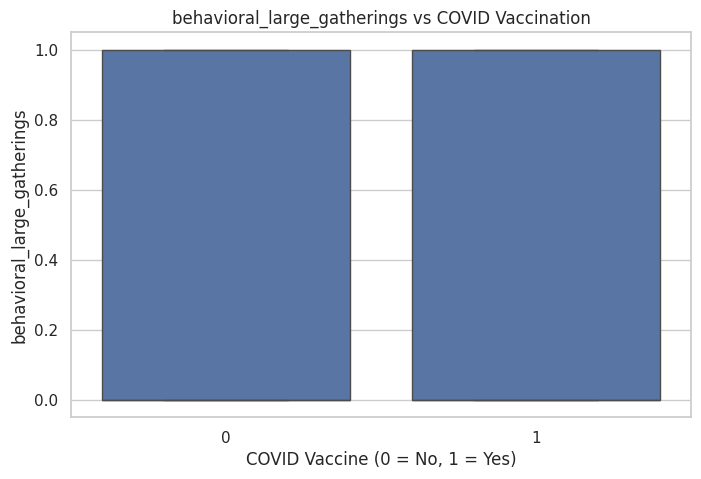

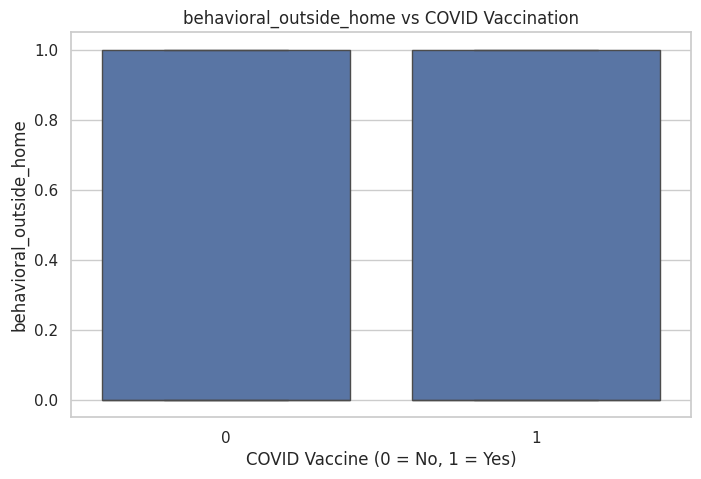

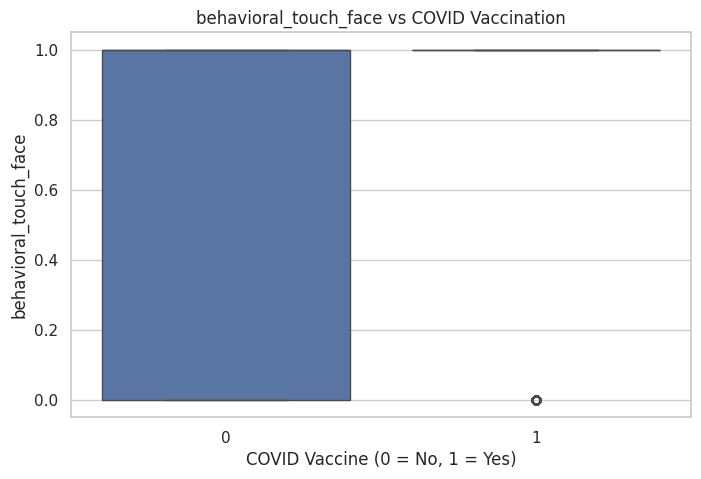

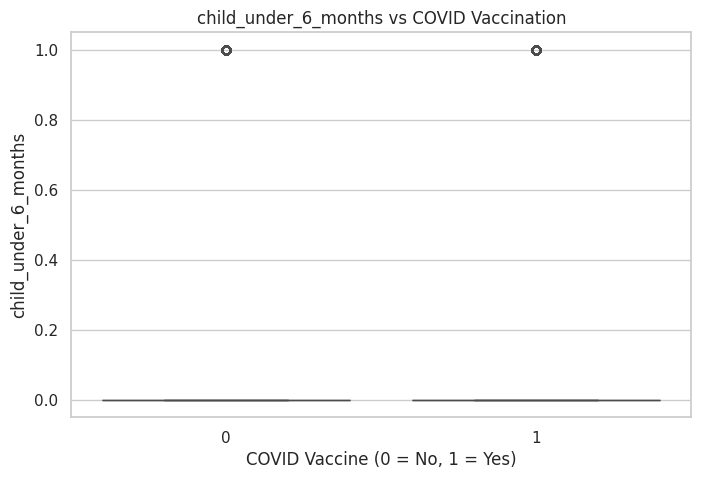

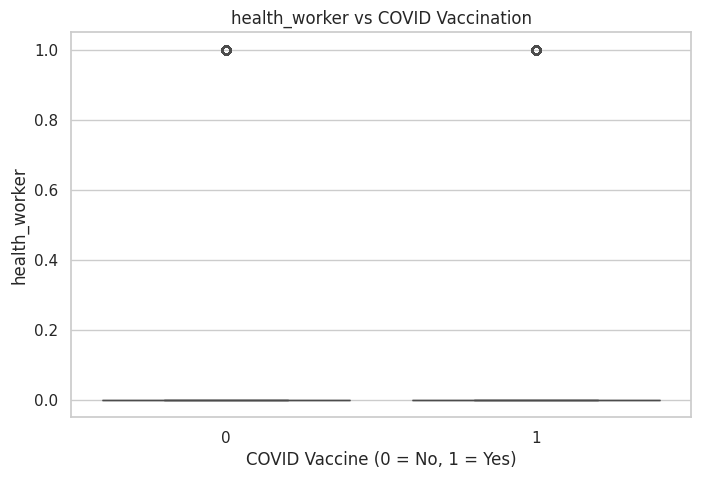

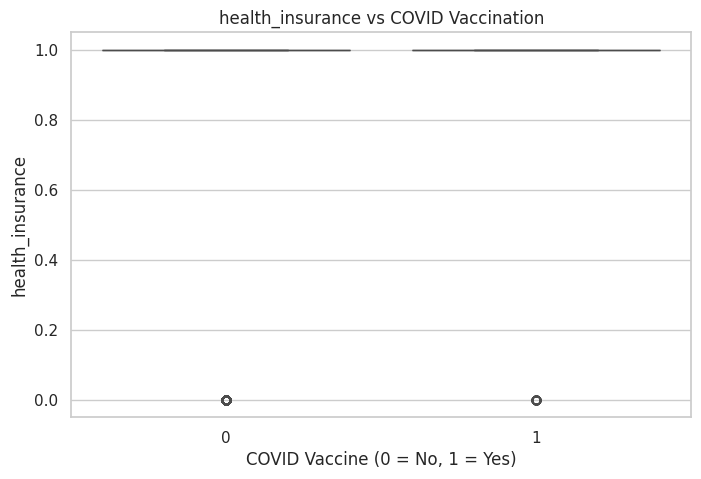

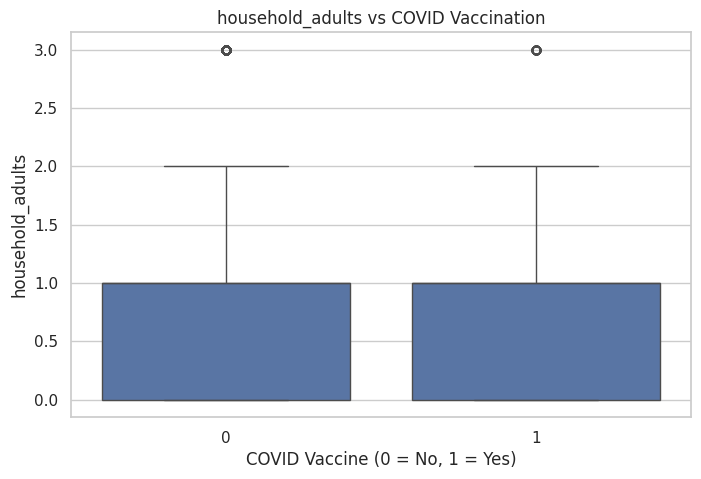

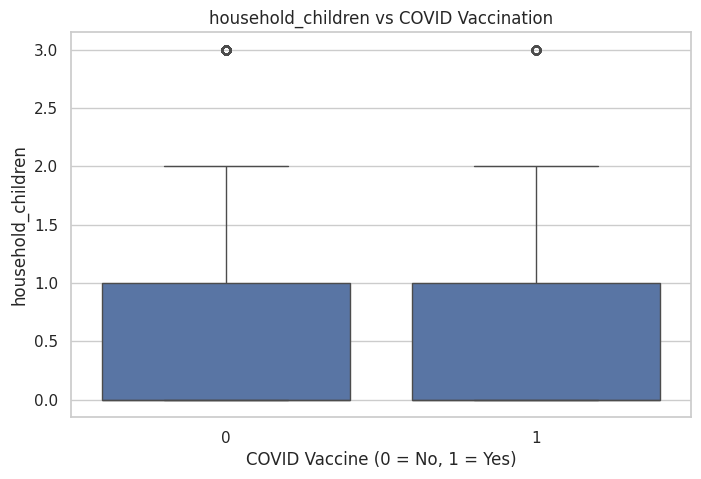

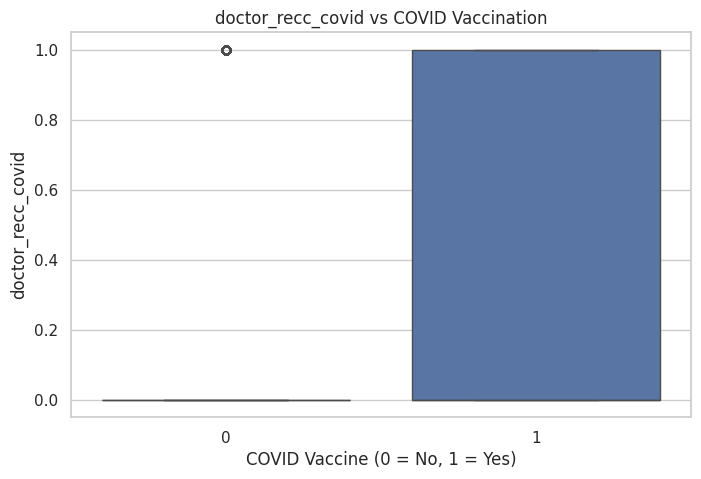

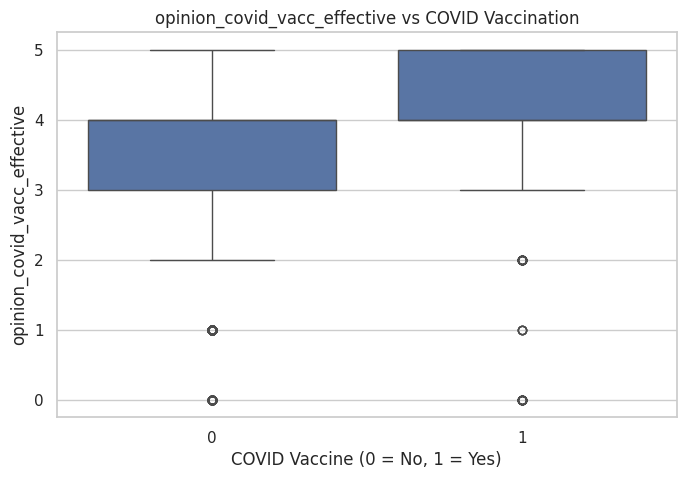

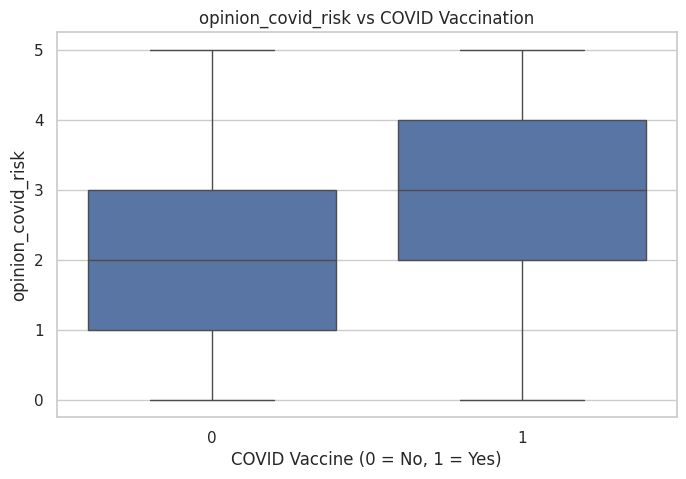

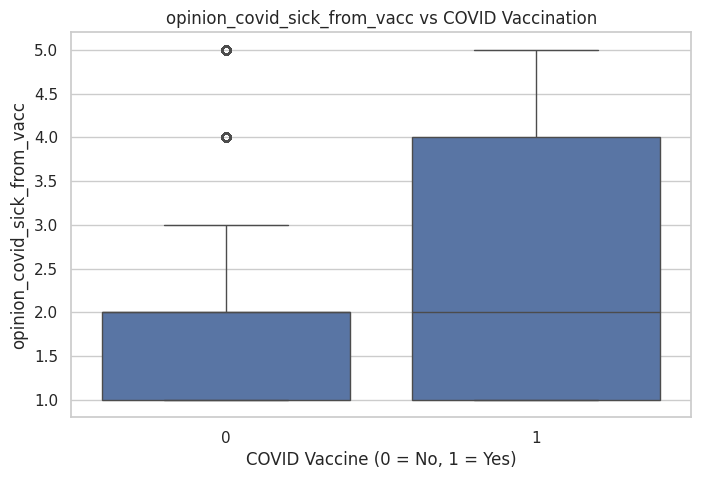

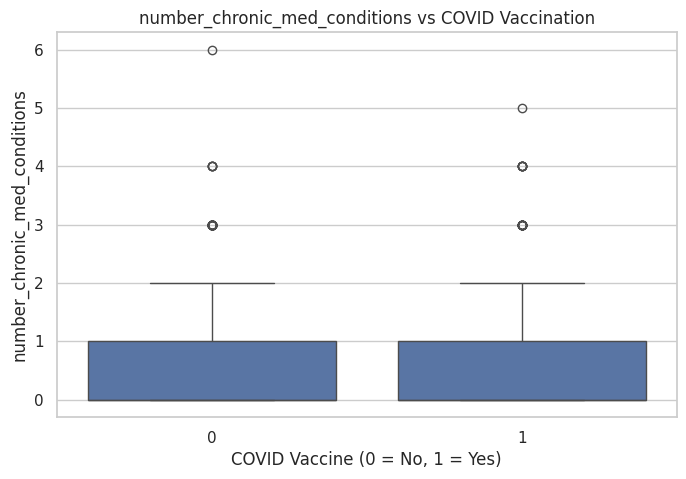

In [ ]:

# Cell 14: Numerical features vs target

for col in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=train,
        x="covid_vaccine",
        y=col
    )

    plt.title(f"{col} vs COVID Vaccination")
    plt.xlabel("COVID Vaccine (0 = No, 1 = Yes)")
    plt.ylabel(col)

    plt.show()


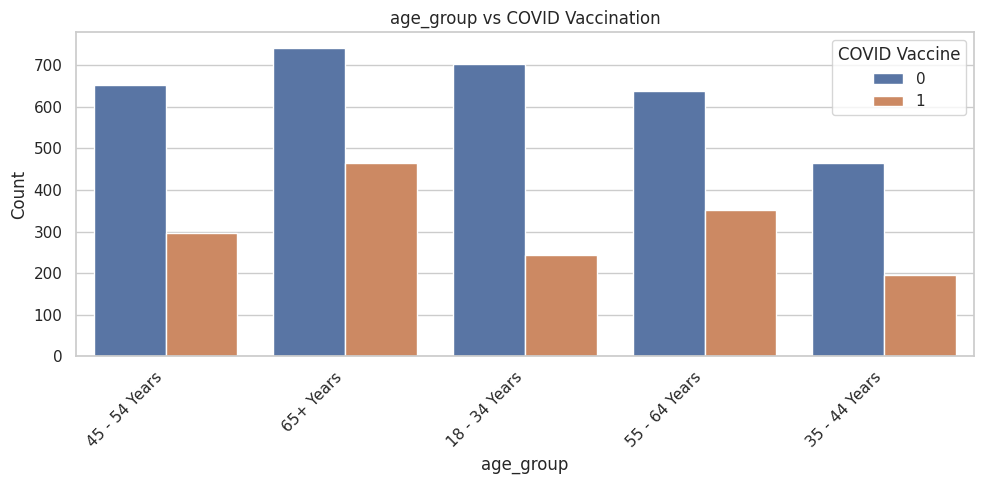

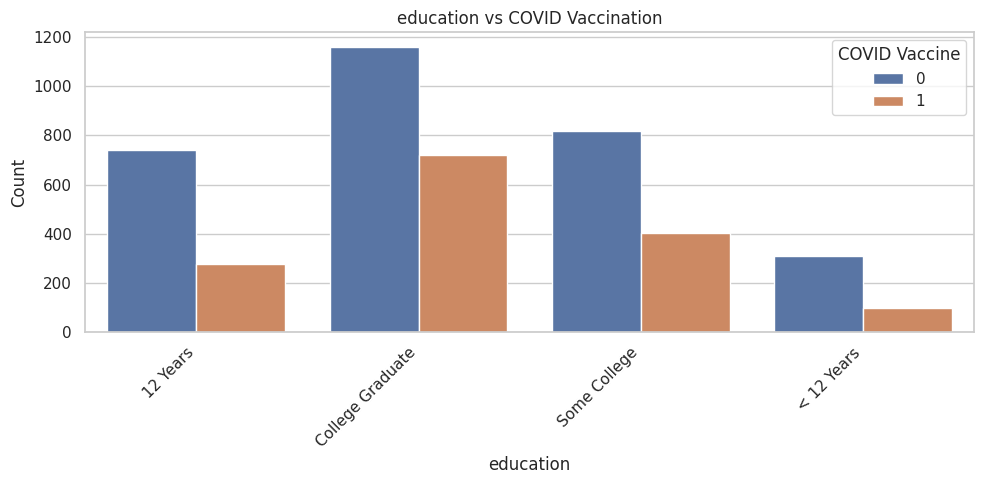

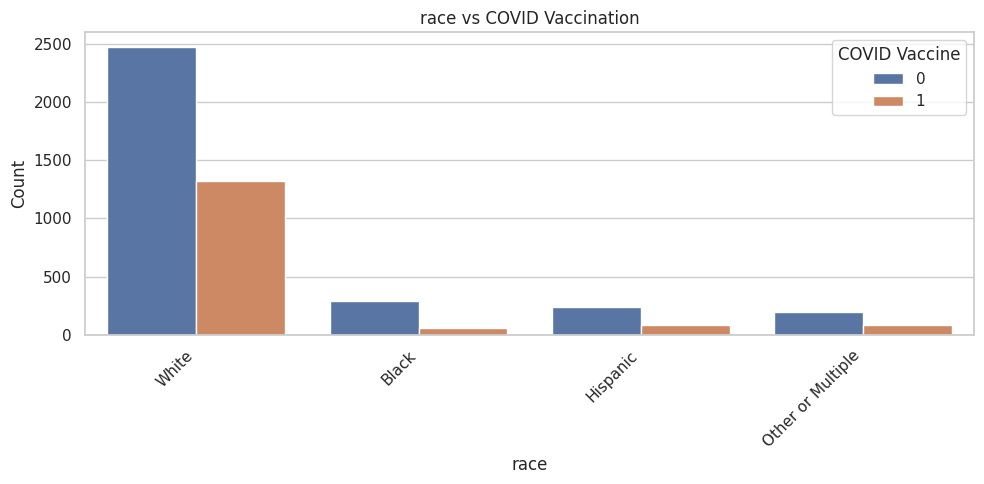

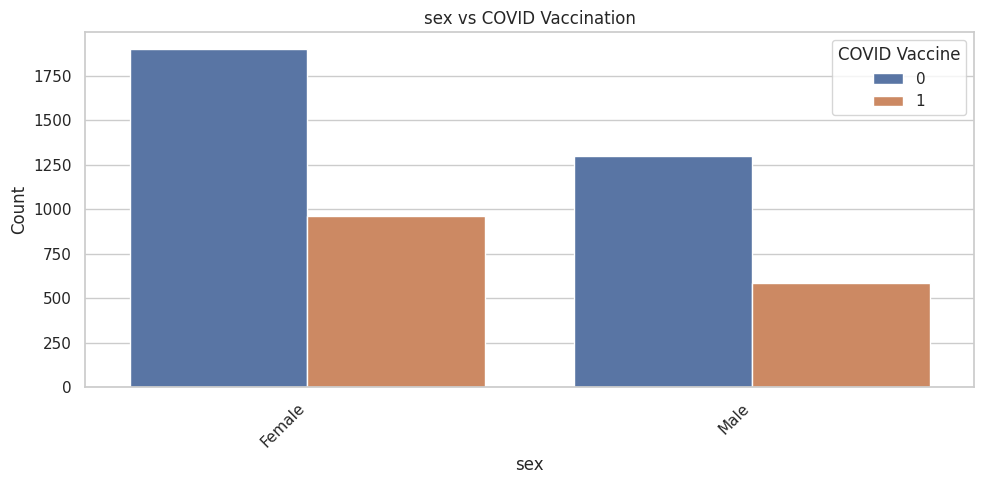

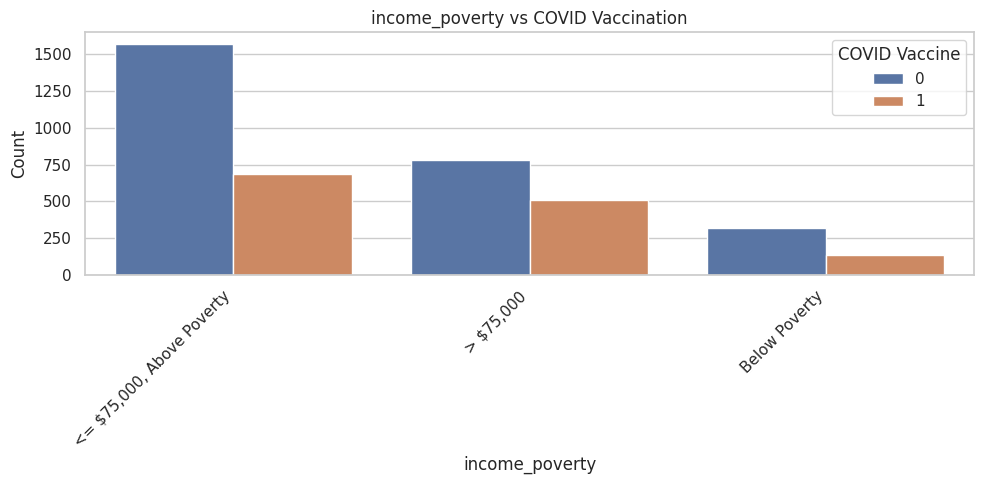

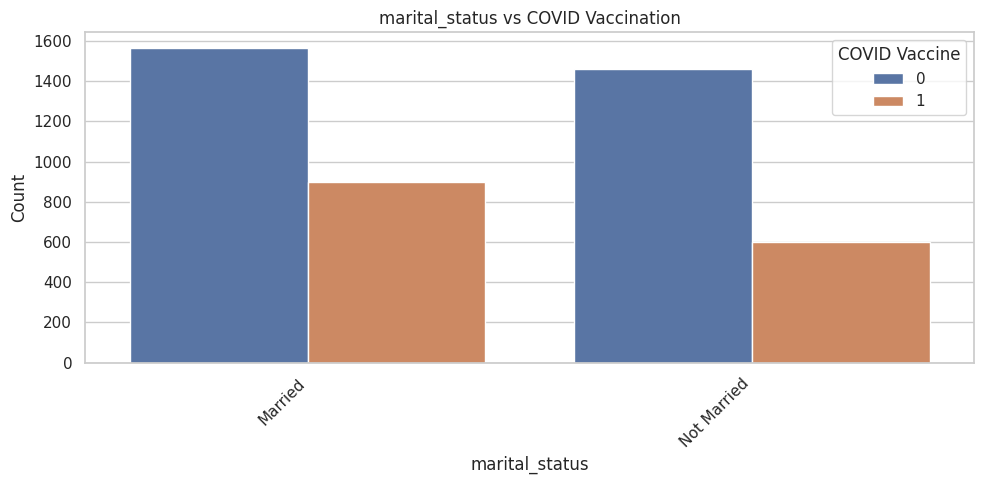

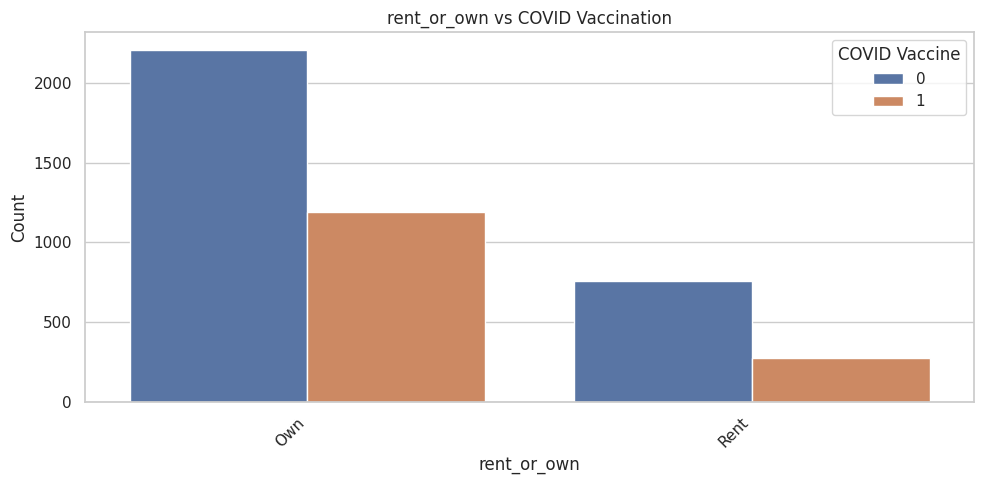

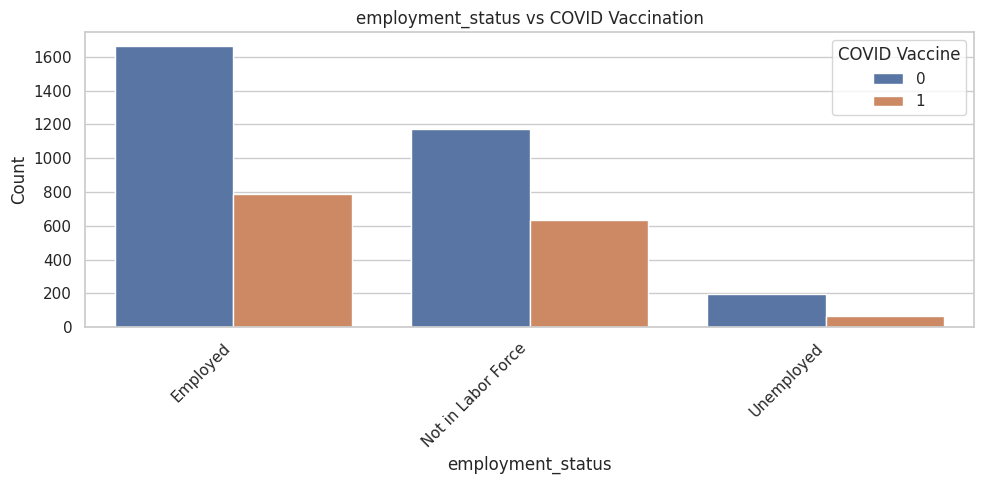

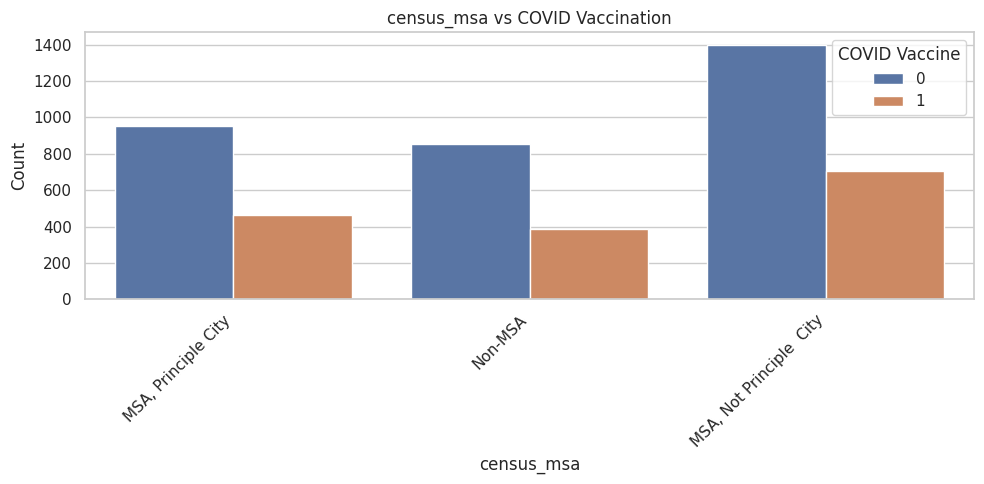

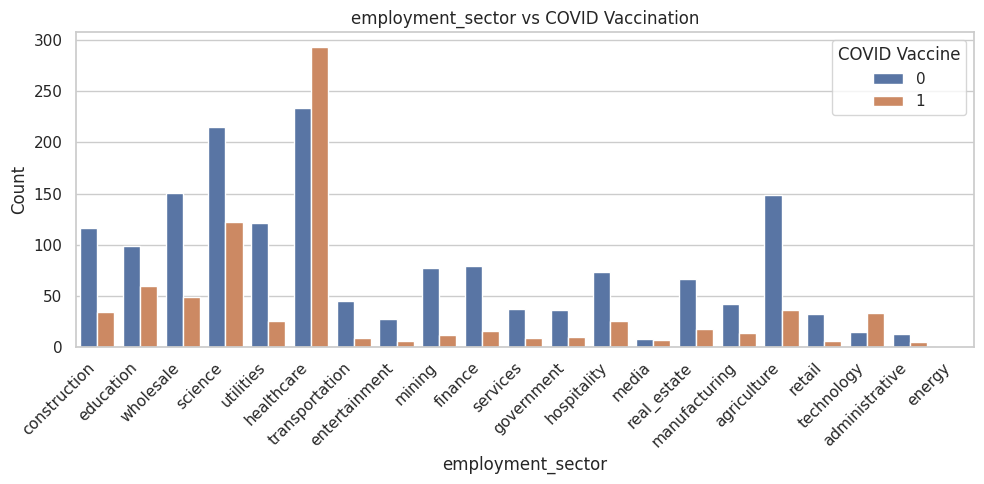

In [ ]:

# Cell 15: Categorical features vs target

for col in categorical_columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train,
        x=col,
        hue="covid_vaccine"
    )

    plt.title(f"{col} vs COVID Vaccination")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="COVID Vaccine")

    plt.tight_layout()
    plt.show()


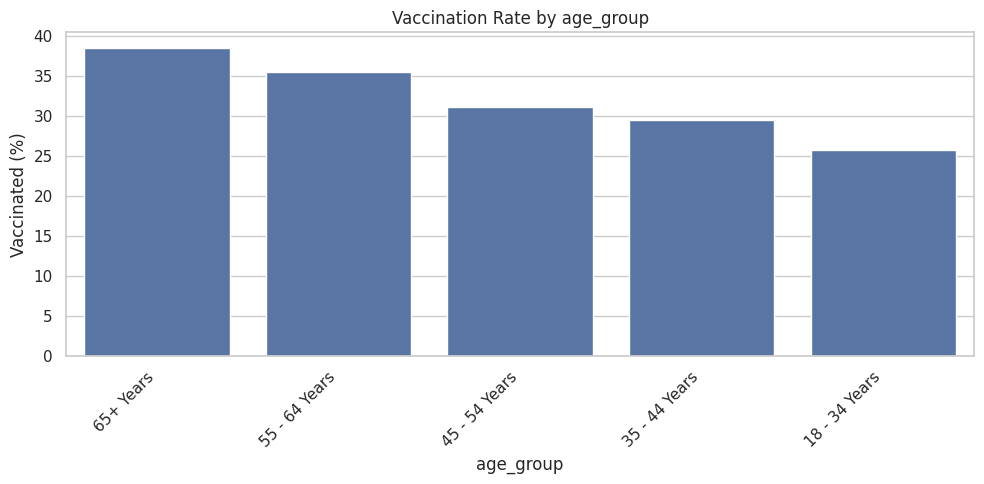

,covid_vaccine
age_group,
65+ Years,38.576159
55 - 64 Years,35.584677
45 - 54 Years,31.223629
35 - 44 Years,29.500756
18 - 34 Years,25.765576


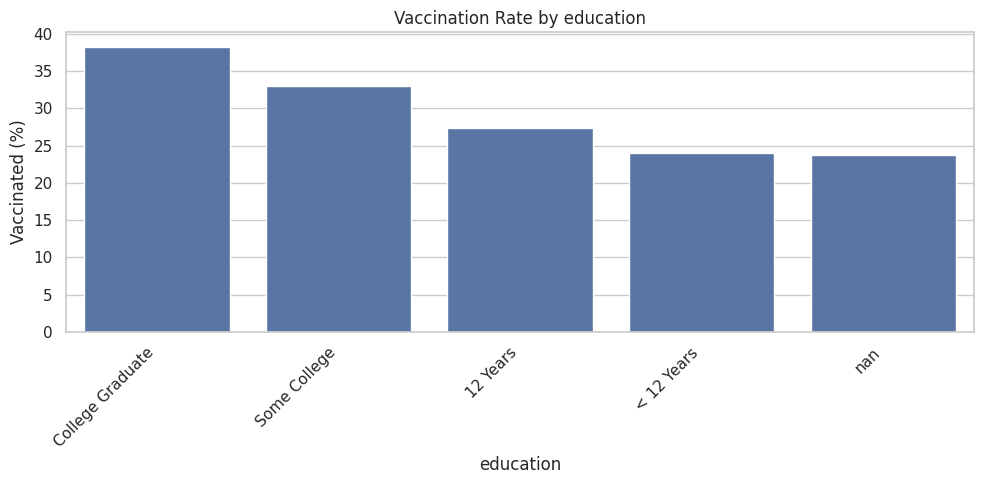

,covid_vaccine
education,
College Graduate,38.289963
Some College,33.060556
12 Years,27.308448
< 12 Years,23.950617
NaN,23.684211


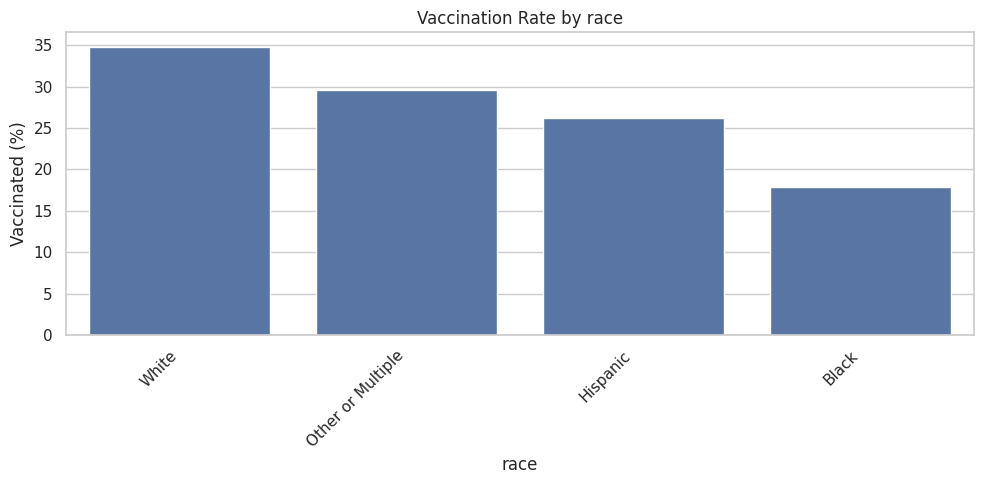

,covid_vaccine
race,
White,34.834123
Other or Multiple,29.577465
Hispanic,26.168224
Black,17.847025


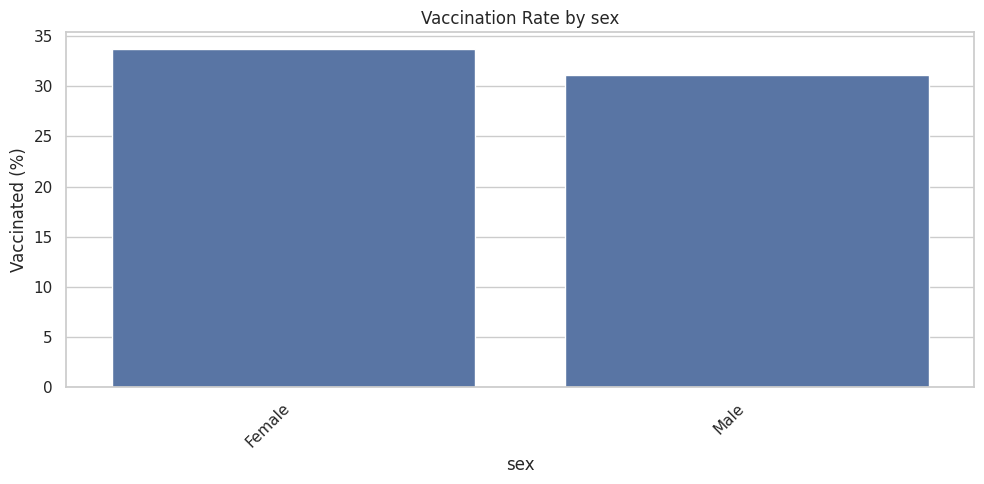

,covid_vaccine
sex,
Female,33.682373
Male,31.147541


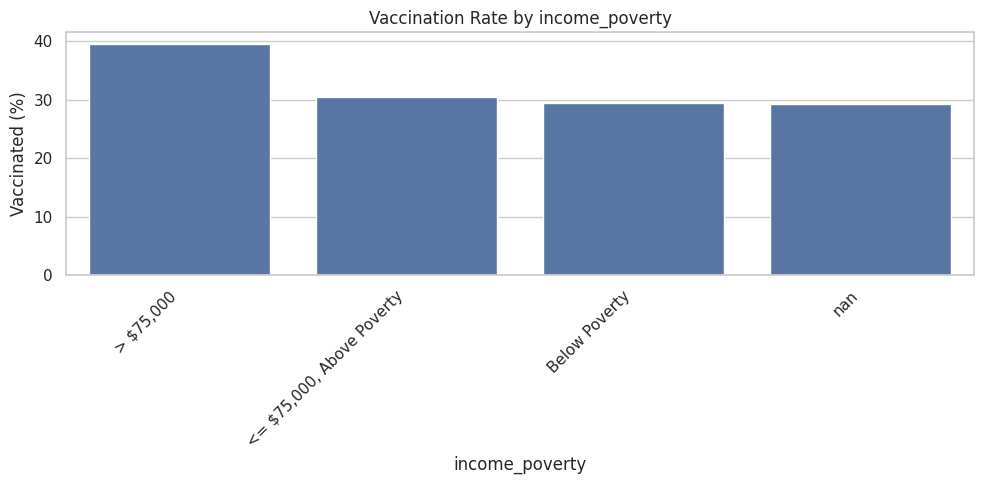

,covid_vaccine
income_poverty,
"> $75,000",39.536680
"<= $75,000, Above Poverty",30.509978
Below Poverty,29.475983
NaN,29.278075


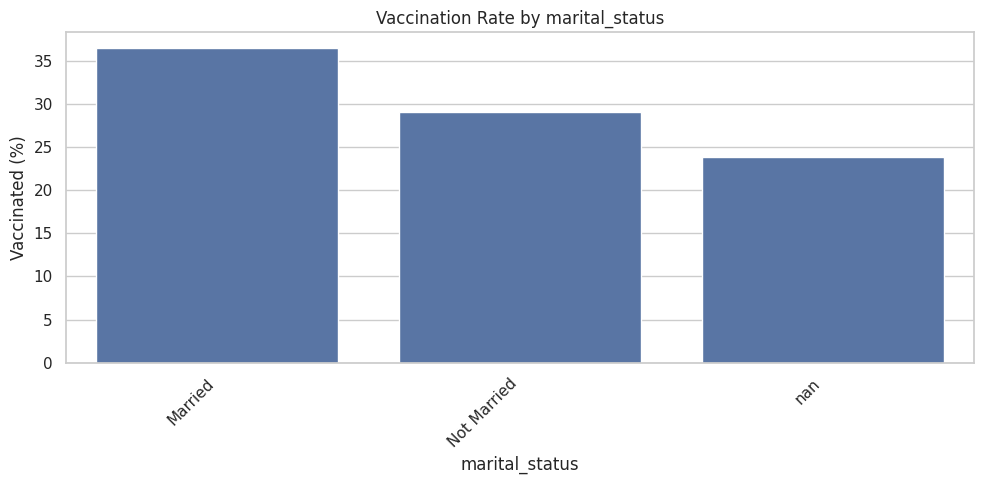

,covid_vaccine
marital_status,
Married,36.485390
Not Married,29.112082
NaN,23.809524


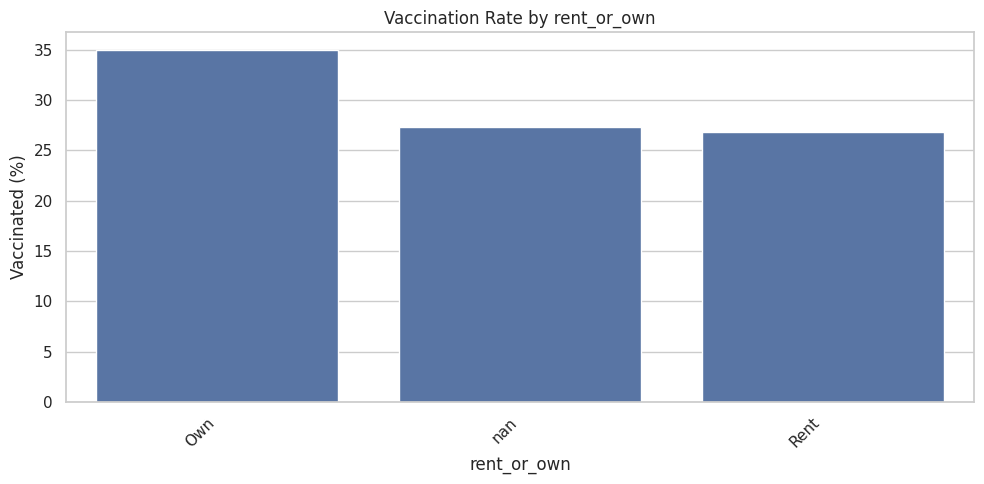

,covid_vaccine
rent_or_own,
Own,34.983790
NaN,27.355623
Rent,26.789168


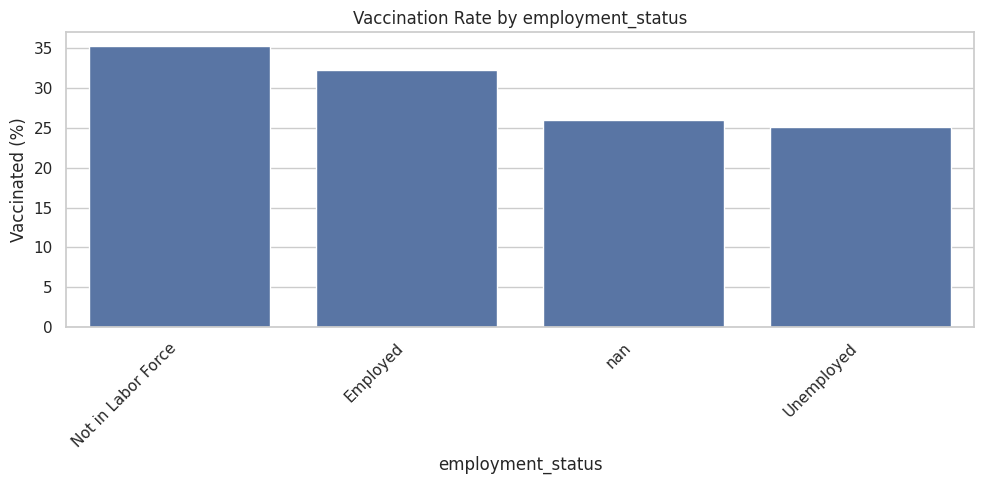

,covid_vaccine
employment_status,
Not in Labor Force,35.232301
Employed,32.231742
NaN,26.050420
Unemployed,25.096525


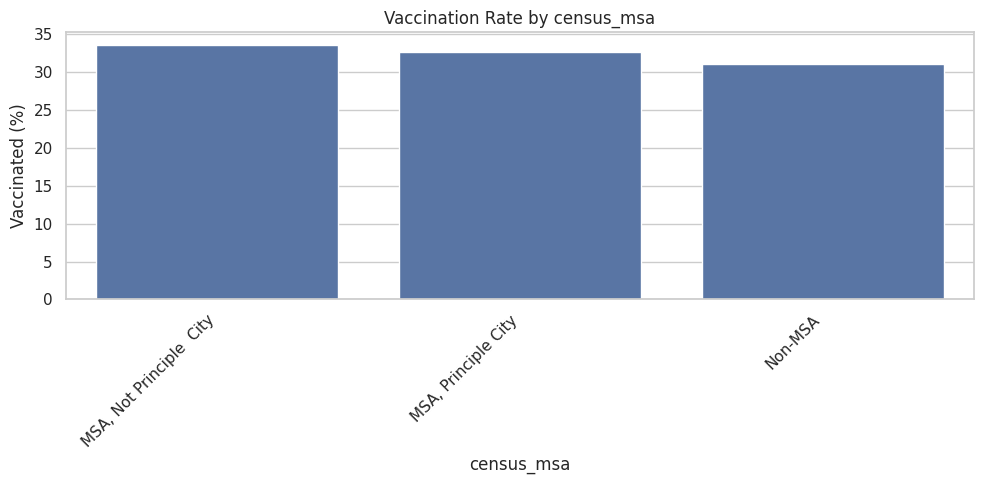

,covid_vaccine
census_msa,
"MSA, Not Principle City",33.602662
"MSA, Principle City",32.696391
Non-MSA,31.073446


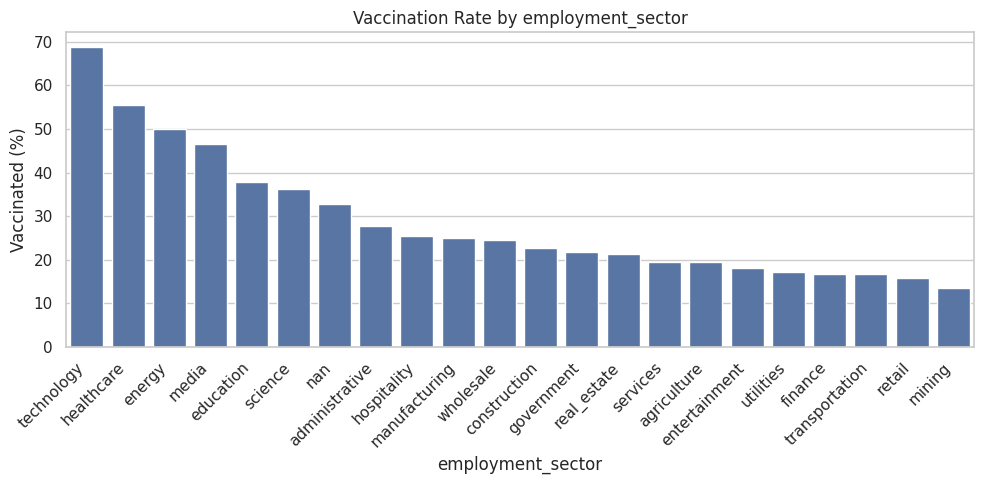

,covid_vaccine
employment_sector,
technology,68.750000
healthcare,55.597723
energy,50.000000
media,46.666667
education,37.735849
science,36.201780
NaN,32.789700
administrative,27.777778
hospitality,25.510204


In [ ]:

# Cell 16: Vaccination percentage by category

for col in categorical_columns:

    vaccination_rate = (
        train.groupby(col, dropna=False)["covid_vaccine"]
        .mean() * 100
    )

    vaccination_rate = vaccination_rate.sort_values(
        ascending=False
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=vaccination_rate.index.astype(str),
        y=vaccination_rate.values
    )

    plt.title(f"Vaccination Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Vaccinated (%)")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

    display(vaccination_rate)


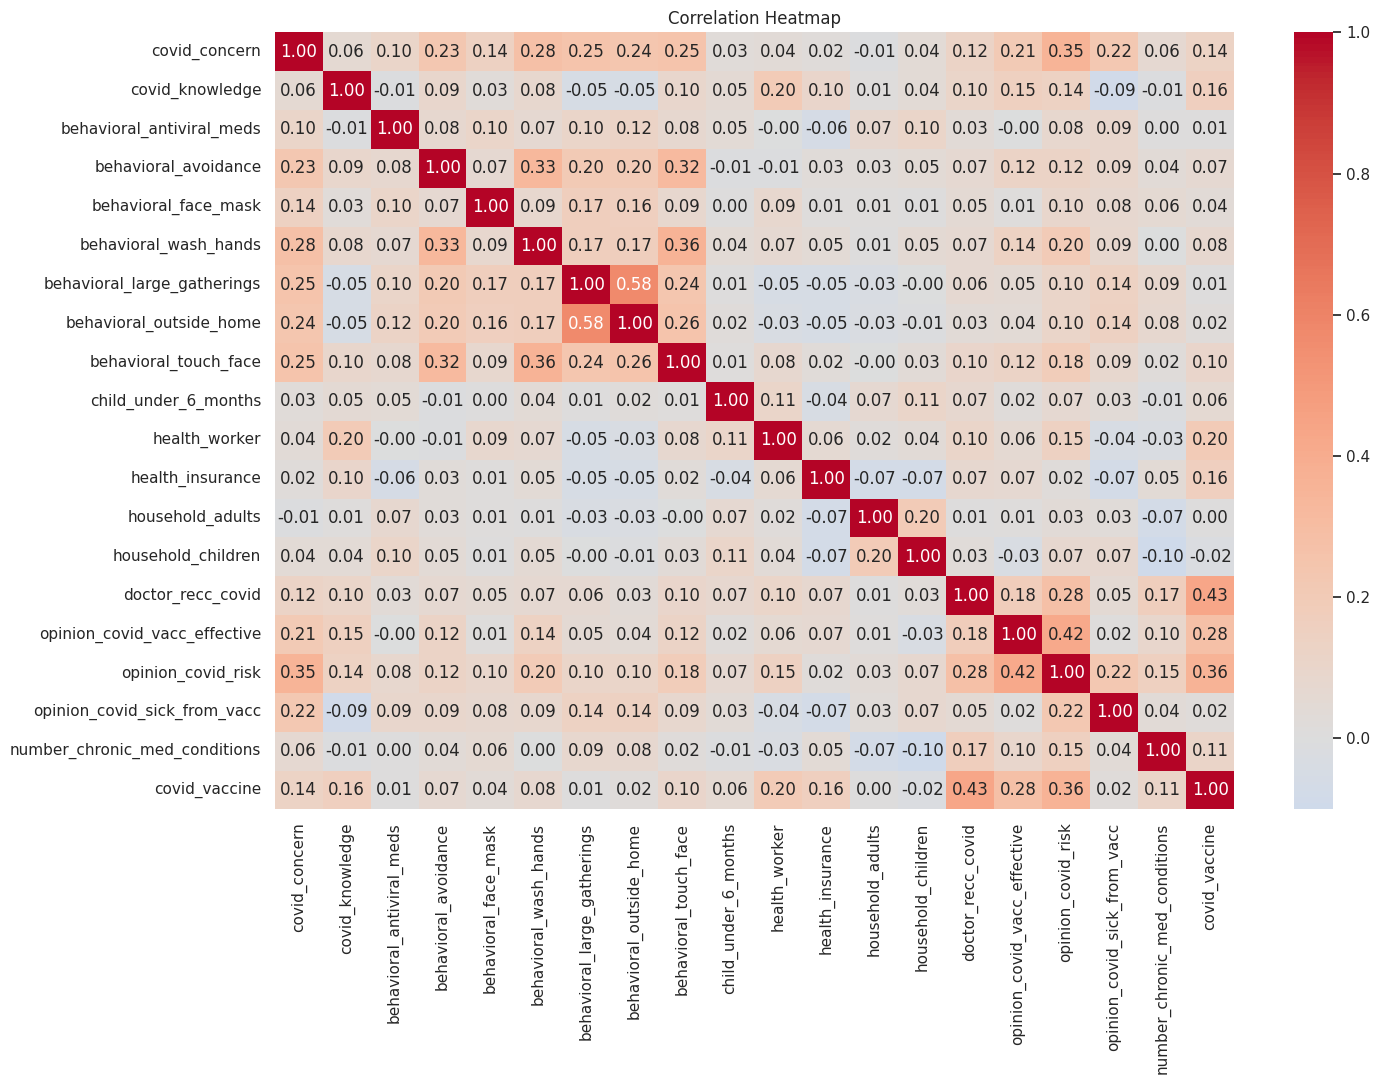

In [ ]:

# Cell 17: Correlation analysis

correlation = train[
    numerical_columns + ["covid_vaccine"]
].corr()

plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


,covid_vaccine
doctor_recc_covid,0.430375
opinion_covid_risk,0.364942
opinion_covid_vacc_effective,0.277309
health_worker,0.197199
health_insurance,0.164584
covid_knowledge,0.164260
covid_concern,0.135191
number_chronic_med_conditions,0.114983
behavioral_touch_face,0.097420
behavioral_wash_hands,0.075328


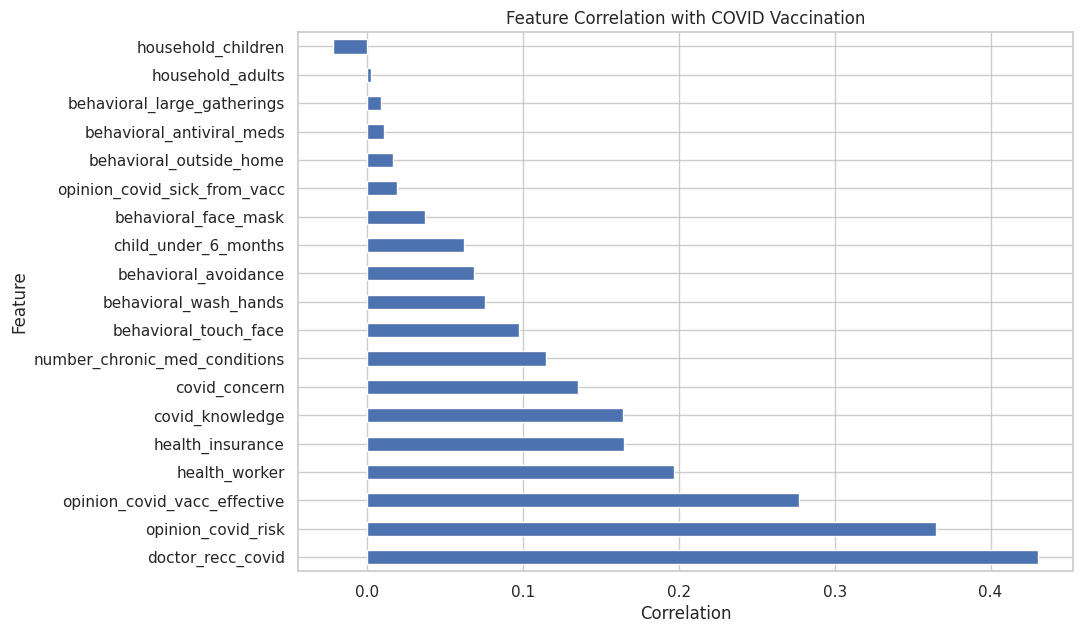

In [ ]:

# Cell 18: Correlation ranking

target_correlation = (
    correlation["covid_vaccine"]
    .drop("covid_vaccine")
    .sort_values(ascending=False)
)

display(target_correlation)

plt.figure(figsize=(10, 7))

target_correlation.plot(
    kind="barh"
)

plt.title("Feature Correlation with COVID Vaccination")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()


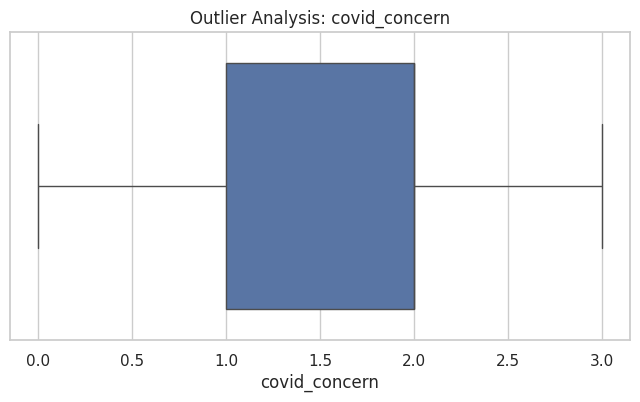

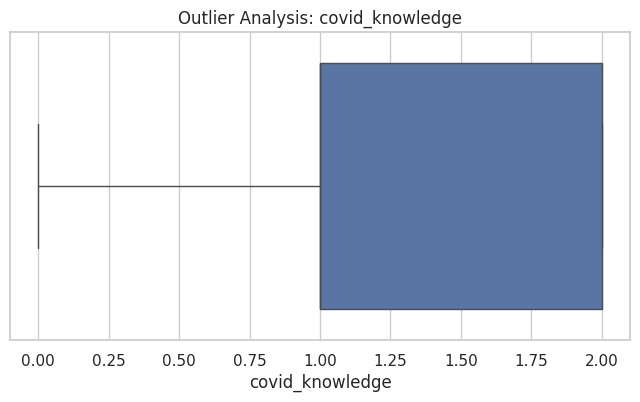

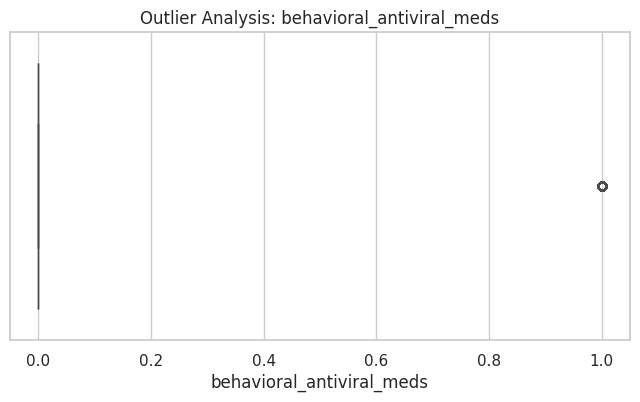

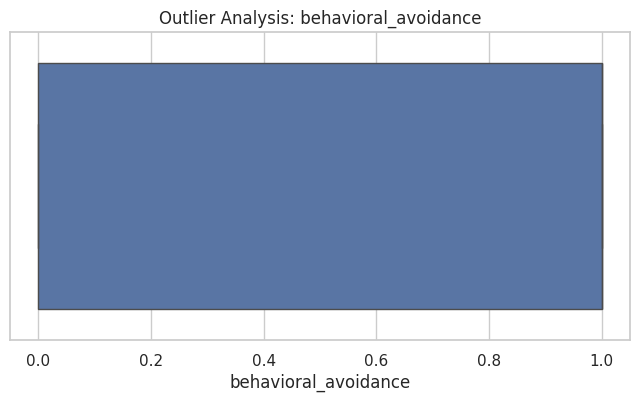

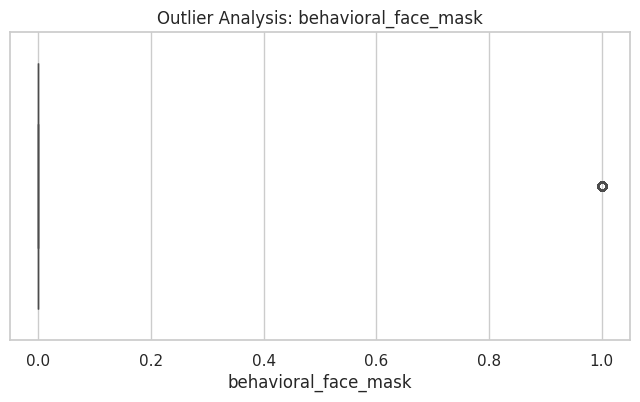

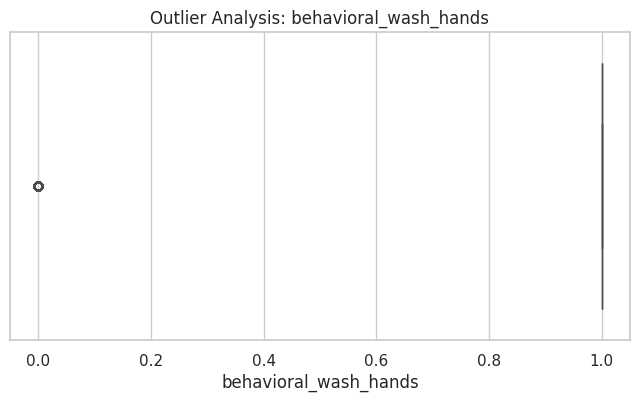

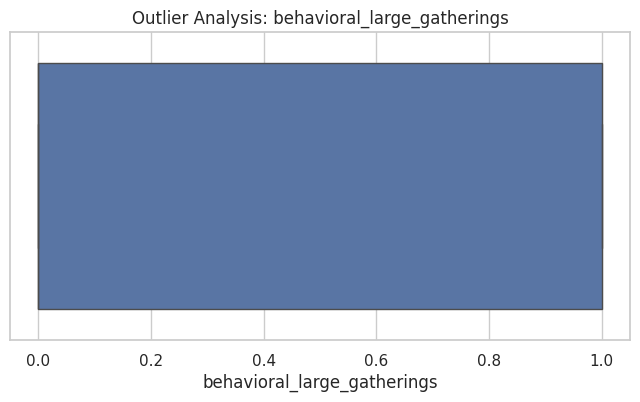

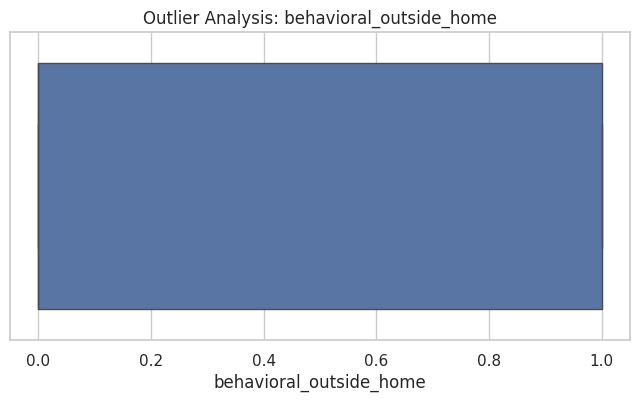

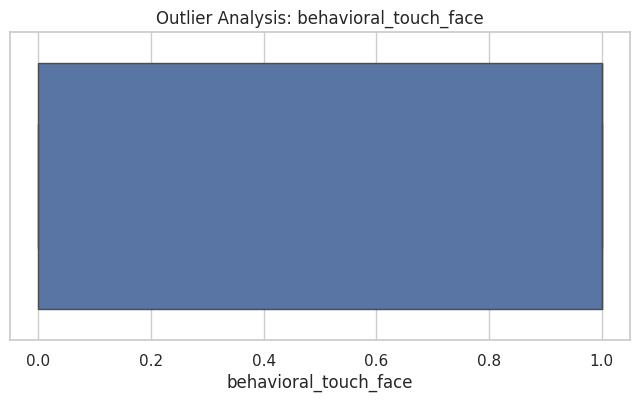

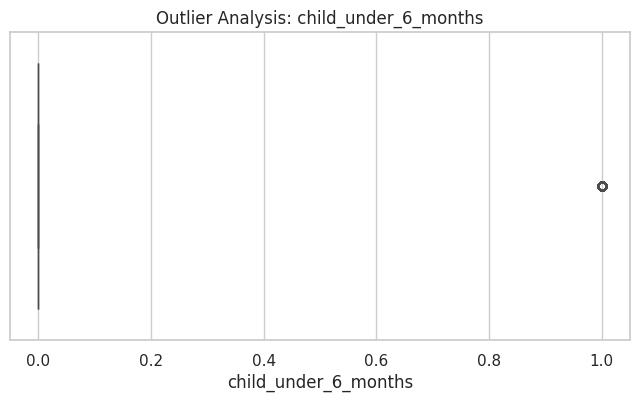

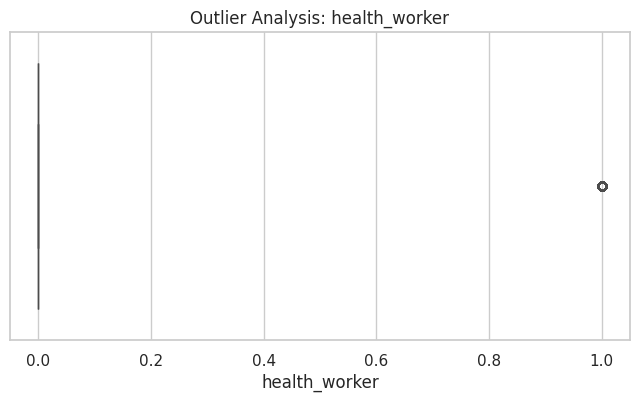

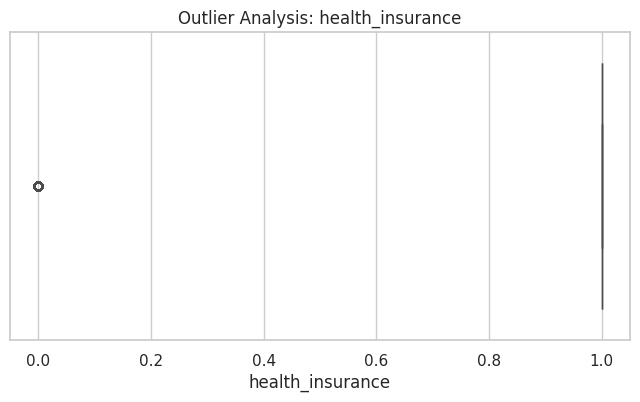

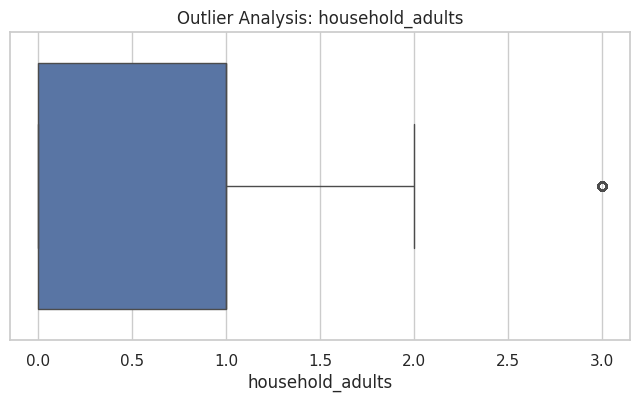

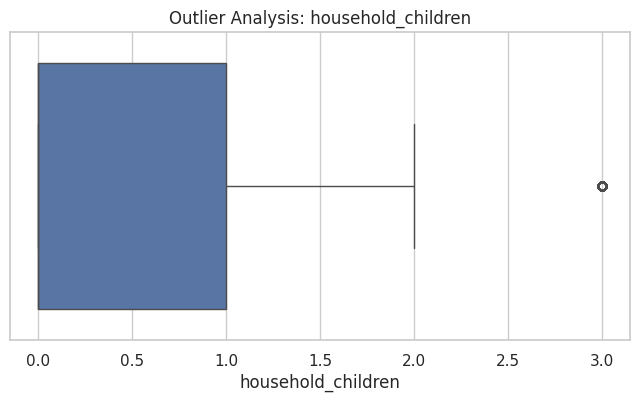

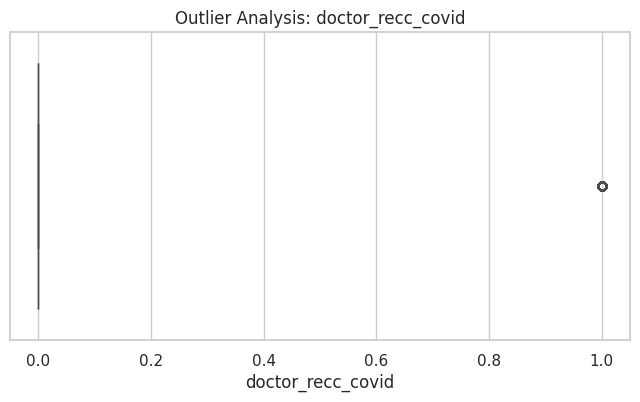

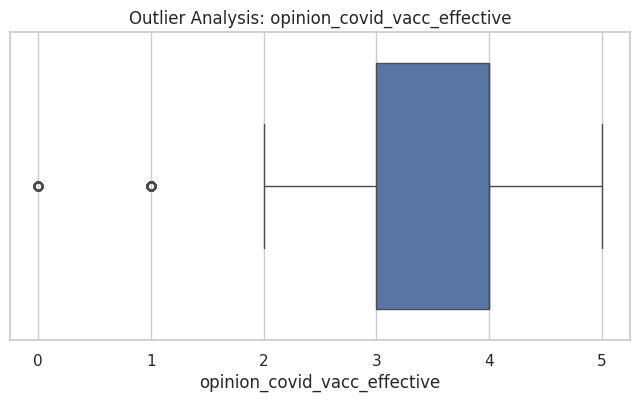

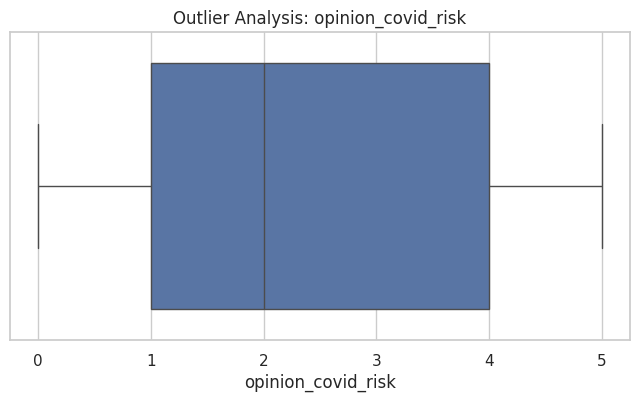

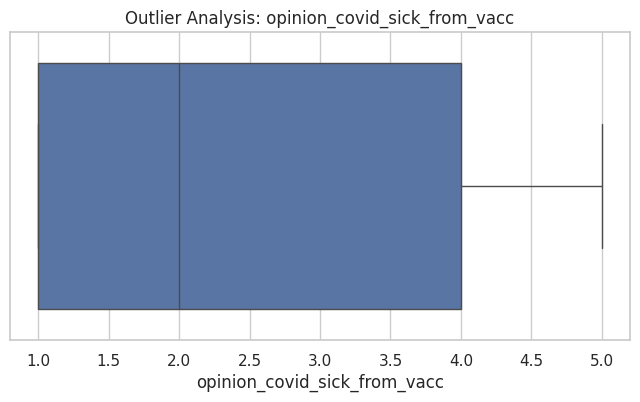

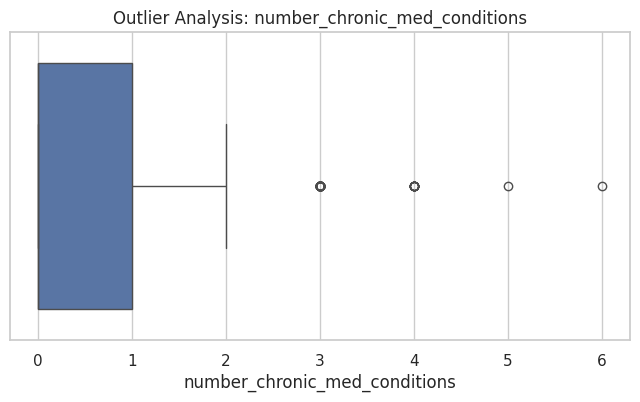

In [ ]:

# Cell 19: Boxplots for numerical variables

for col in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=train[col]
    )

    plt.title(f"Outlier Analysis: {col}")
    plt.show()


In [ ]:

# Cell 20: Calculate outliers using IQR

outlier_summary = []

for col in numerical_columns:

    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (train[col] < lower) |
        (train[col] > upper)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": outliers
    })

display(pd.DataFrame(outlier_summary))


,Feature,Lower_Bound,Upper_Bound,Outlier_Count
0,covid_concern,-0.5,3.5,0
1,covid_knowledge,-0.5,3.5,0
2,behavioral_antiviral_meds,0.0,0.0,253
3,behavioral_avoidance,-1.5,2.5,0
4,behavioral_face_mask,0.0,0.0,347
5,behavioral_wash_hands,1.0,1.0,763
6,behavioral_large_gatherings,-1.5,2.5,0
7,behavioral_outside_home,-1.5,2.5,0
8,behavioral_touch_face,-1.5,2.5,0
9,child_under_6_months,0.0,0.0,431


In [ ]:

# Cell 21: Prepare X and y

X = train.drop(
    columns=["covid_vaccine", "respondent_id"]
)

y = train["covid_vaccine"]

# Preserve test IDs for submission
test_ids = test["respondent_id"].copy()

X_test = test.drop(
    columns=["respondent_id"]
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)


X shape: (4756, 29)
y shape: (4756,)
X_test shape: (4749, 29)


In [ ]:

# Cell 22: Identify numerical and categorical features

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']
Categorical features: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


In [ ]:

# Cell 23: Numerical preprocessing

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [ ]:

# Cell 24: Split data into training and validation

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))


Training samples: 3804
Validation samples: 952

Training target distribution:
covid_vaccine
0    0.673239
1    0.326761
Name: proportion, dtype: float64

Validation target distribution:
covid_vaccine
0    0.673319
1    0.326681
Name: proportion, dtype: float64


In [ ]:

# Cell 25: Baseline model

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

print("Baseline Accuracy:",
      accuracy_score(y_val, baseline_predictions))

print("Baseline F1:",
      f1_score(y_val, baseline_predictions))


Baseline Accuracy: 0.6733193277310925
Baseline F1: 0.0


In [ ]:

# Cell 26: Define machine learning models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": __import__(
        "sklearn.svm",
        fromlist=["SVC"]
    ).SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

print("Models created successfully!")


Models created successfully!


In [ ]:

# Cell 27: Train and compare models

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_val, probabilities
        ),
        "PR_AUC": average_precision_score(
            y_val, probabilities
        ),
        "Log_Loss": log_loss(
            y_val, probabilities
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
)

display(results_df)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Log_Loss
0,Logistic Regression,0.769958,0.624324,0.742765,0.678414,0.828238,0.718520,0.508308
1,Random Forest,0.787815,0.717131,0.578778,0.640569,0.826778,0.699818,0.479954
3,SVM,0.771008,0.634783,0.704180,0.667683,0.819274,0.694213,0.477807
2,Extra Trees,0.772059,0.725962,0.485531,0.581888,0.812028,0.679559,0.488686


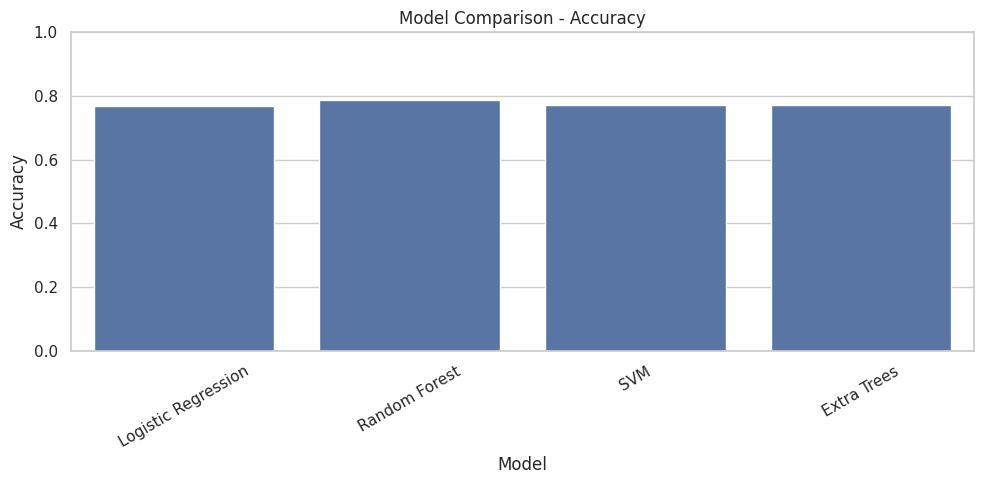

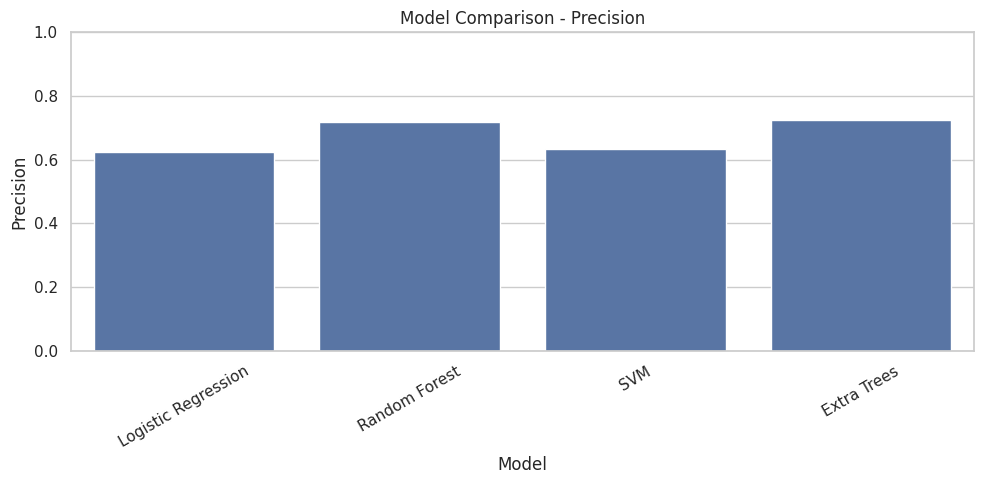

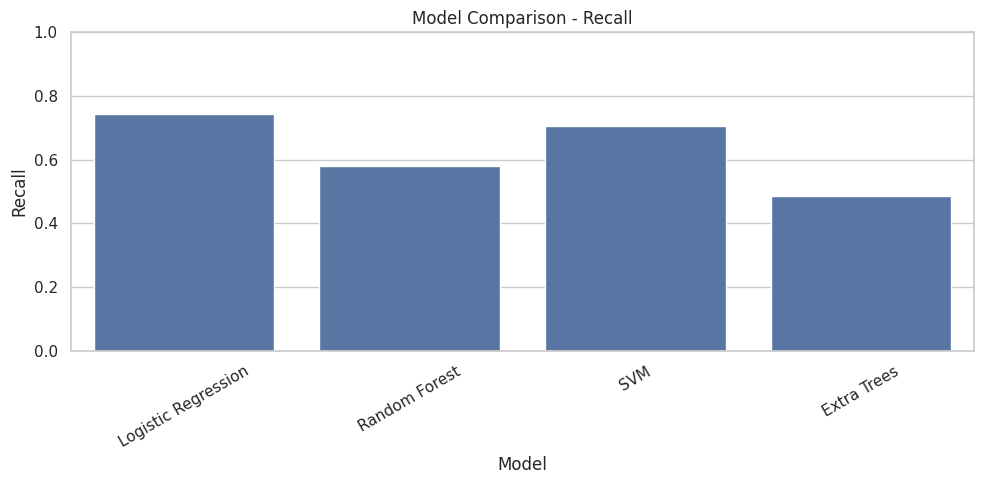

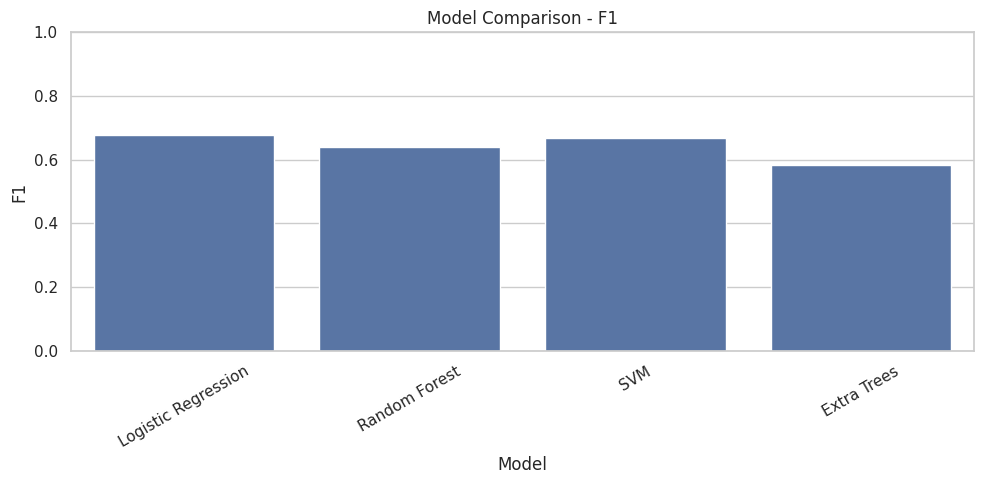

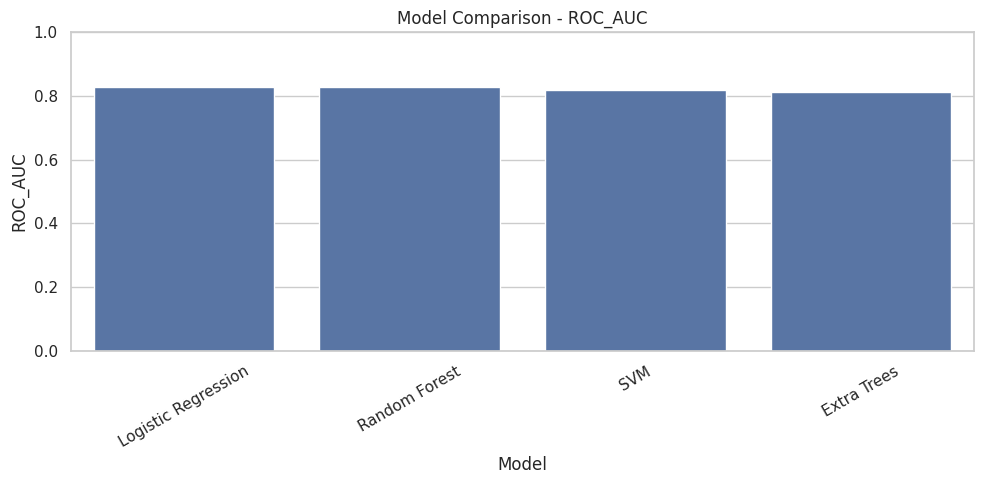

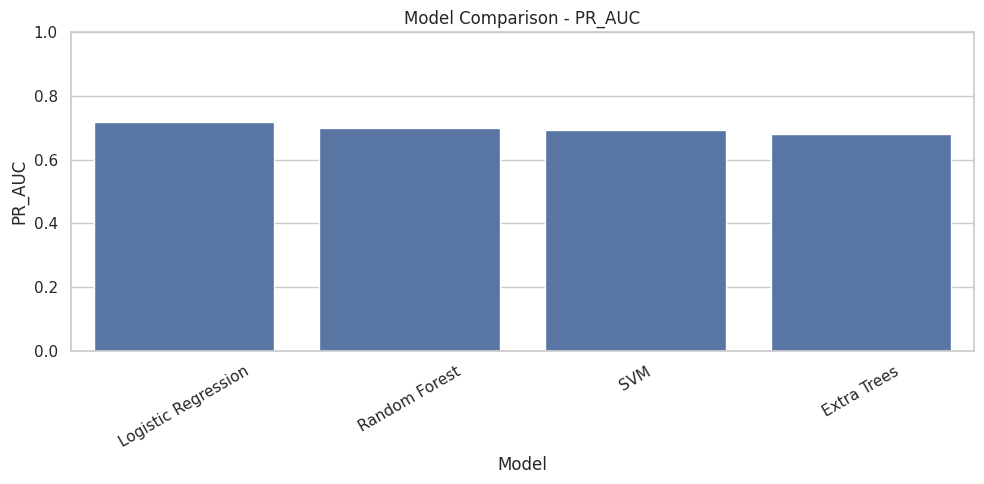

In [ ]:

# Cell 28: Compare model performance

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=30)
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()


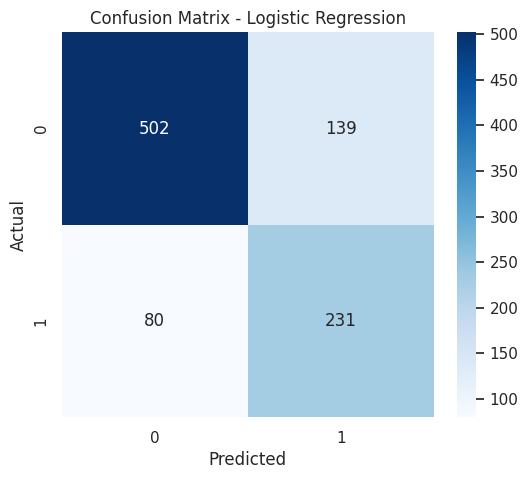

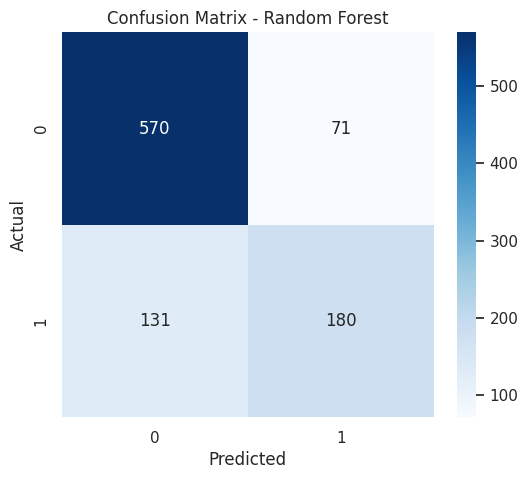

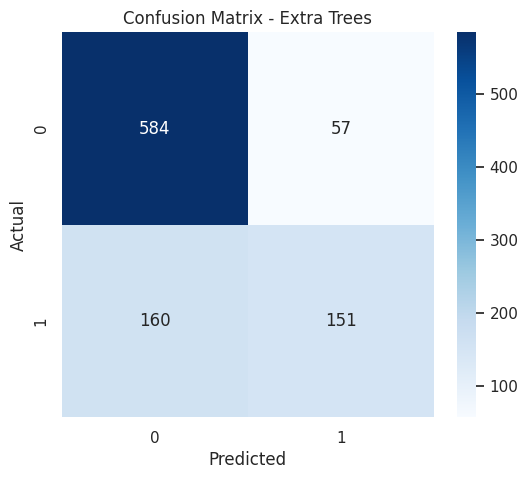

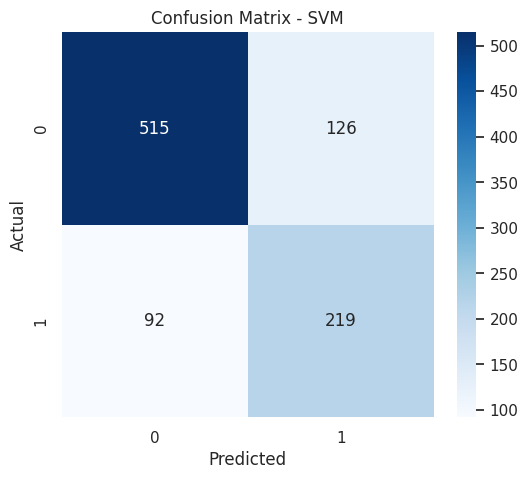

In [ ]:

# Cell 29: Confusion matrix for each model

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_val)

    cm = confusion_matrix(y_val, predictions)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()


In [ ]:

# Cell 30: Detailed classification reports

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_val)

    print("\nMODEL:", name)
    print("=" * 60)

    print(
        classification_report(
            y_val,
            predictions,
            target_names=[
                "Not Vaccinated",
                "Vaccinated"
            ]
        )
    )



MODEL: Logistic Regression
                precision    recall  f1-score   support

Not Vaccinated       0.86      0.78      0.82       641
    Vaccinated       0.62      0.74      0.68       311

      accuracy                           0.77       952
     macro avg       0.74      0.76      0.75       952
  weighted avg       0.78      0.77      0.77       952


MODEL: Random Forest
                precision    recall  f1-score   support

Not Vaccinated       0.81      0.89      0.85       641
    Vaccinated       0.72      0.58      0.64       311

      accuracy                           0.79       952
     macro avg       0.77      0.73      0.75       952
  weighted avg       0.78      0.79      0.78       952


MODEL: Extra Trees
                precision    recall  f1-score   support

Not Vaccinated       0.78      0.91      0.84       641
    Vaccinated       0.73      0.49      0.58       311

      accuracy                           0.77       952
     macro avg       0.76 

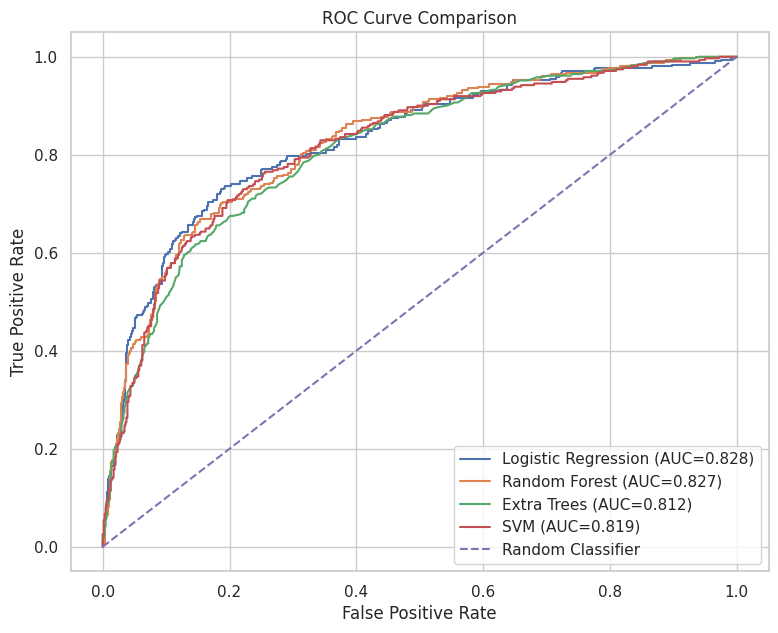

In [ ]:

# Cell 31: Compare ROC curves

plt.figure(figsize=(9, 7))

for name, pipeline in trained_models.items():

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_val,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


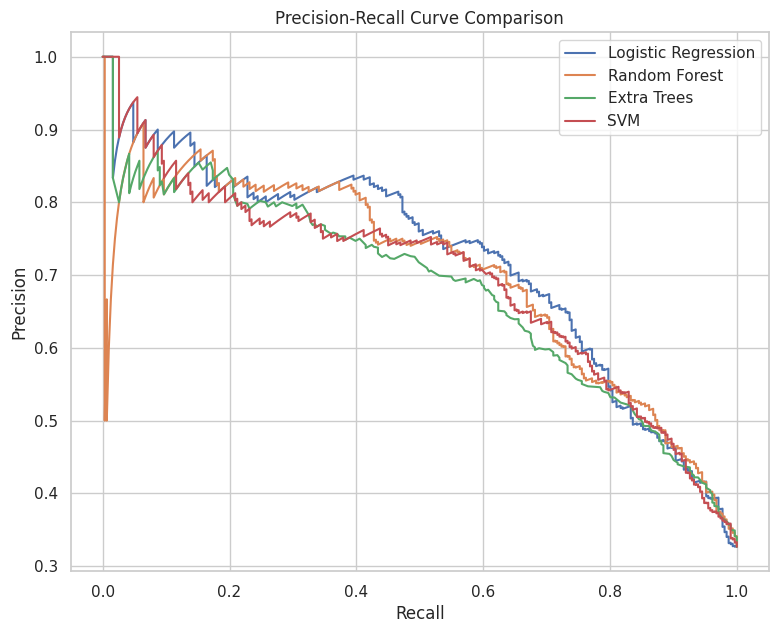

In [ ]:

# Cell 32: Precision-recall curves

plt.figure(figsize=(9, 7))

for name, pipeline in trained_models.items():

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()


In [ ]:

# Cell 33: Evaluation metrics

print("ROC-AUC:", results_df["ROC_AUC"].max())
print("PR-AUC:", results_df["PR_AUC"].max())
print("Best F1:", results_df["F1"].max())
print("Lowest Log Loss:", results_df["Log_Loss"].min())


ROC-AUC: 0.8282376311129614
PR-AUC: 0.7185201288019344
Best F1: 0.6784140969162996
Lowest Log Loss: 0.477806520035831


In [ ]:

# Cell 34: Threshold analysis for the best model

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

val_probabilities = best_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)


,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.410714,0.354312,0.977492,0.520103
1,0.15,0.487395,0.386684,0.971061,0.553114
2,0.20,0.548319,0.416315,0.951768,0.579256
3,0.25,0.602941,0.447244,0.913183,0.600423
4,0.30,0.644958,0.476357,0.874598,0.616780
5,0.35,0.678571,0.504873,0.832797,0.628641
6,0.40,0.709034,0.536481,0.803859,0.643501
7,0.45,0.742647,0.578947,0.778135,0.663923
8,0.50,0.769958,0.624324,0.742765,0.678414
9,0.55,0.786765,0.658824,0.720257,0.688172


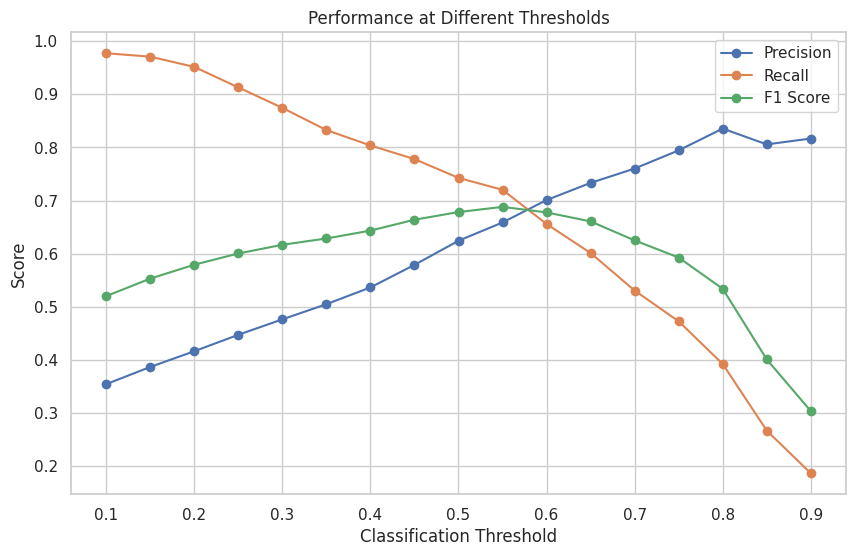

In [ ]:

# Cell 35: Threshold performance visualisation

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision",
    marker="o"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall",
    marker="o"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1 Score",
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Performance at Different Thresholds")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Cell 36: Best threshold according to F1

best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Best threshold:", best_threshold)
print("Best F1:", best_threshold_row["F1"])
print("Precision:", best_threshold_row["Precision"])
print("Recall:", best_threshold_row["Recall"])


Best threshold: 0.5500000000000002
Best F1: 0.6881720430107527
Precision: 0.6588235294117647
Recall: 0.7202572347266881


In [ ]:

# Cell 37: Cross-validation setup

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold Stratified Cross Validation created")


5-fold Stratified Cross Validation created


In [ ]:

# Cell 38: Cross-validation comparison

cv_results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean_ROC_AUC": scores.mean(),
        "Std_ROC_AUC": scores.std(),
        "Minimum_ROC_AUC": scores.min(),
        "Maximum_ROC_AUC": scores.max()
    })

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean_ROC_AUC",
    ascending=False
)

display(cv_df)


,Model,Mean_ROC_AUC,Std_ROC_AUC,Minimum_ROC_AUC,Maximum_ROC_AUC
0,Logistic Regression,0.830533,0.007887,0.820558,0.844197
1,Random Forest,0.830394,0.009311,0.822569,0.846664
3,SVM,0.826532,0.010482,0.814846,0.842765
2,Extra Trees,0.816022,0.007873,0.807265,0.825784


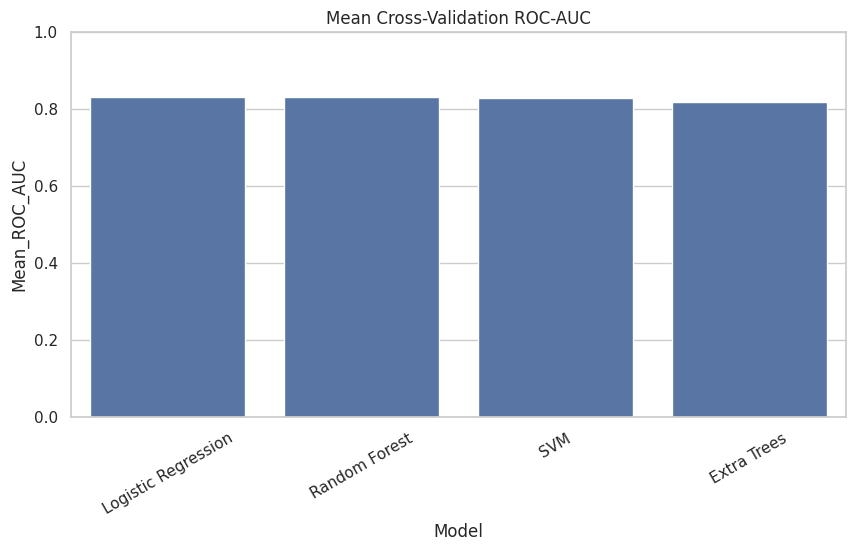

Cross-validation standard deviations:


,Model,Std_ROC_AUC
0,Logistic Regression,0.007887
1,Random Forest,0.009311
3,SVM,0.010482
2,Extra Trees,0.007873


In [40]:

# Cell 39: Cross-validation plot

plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_df,
    x="Model",
    y="Mean_ROC_AUC"
)

plt.title("Mean Cross-Validation ROC-AUC")
plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.show()

print("Cross-validation standard deviations:")
display(
    cv_df[["Model", "Std_ROC_AUC"]]
)


In [41]:

# Cell 40: Hyperparameter search spaces

param_grids = {

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 5, 10, 20],
        "model__solver": ["liblinear", "lbfgs"]
    },

    "Random Forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"]
    },

    "Extra Trees": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"]
    }
}

print("Hyperparameter spaces defined!")


Hyperparameter spaces defined!


In [42]:

# Cell 41: RandomizedSearchCV

tuned_models = {}
tuning_results = []

for name in param_grids:

    print("\nTuning:", name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", models[name])
        ]
    )

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=8,
        scoring="roc_auc",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    tuned_models[name + " Tuned"] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best_CV_ROC_AUC": search.best_score_,
        "Best_Parameters": search.best_params_
    })

    print("Best score:", search.best_score_)
    print("Best parameters:", search.best_params_)

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)



Tuning: Logistic Regression
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best score: 0.8296864975459498
Best parameters: {'model__solver': 'lbfgs', 'model__C': 1}

Tuning: Random Forest
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best score: 0.8336174391020417
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 10}

Tuning: Extra Trees
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best score: 0.8300986747859556
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 10}


,Model,Best_CV_ROC_AUC,Best_Parameters
0,Logistic Regression,0.829686,"{'model__solver': 'lbfgs', 'model__C': 1}"
1,Random Forest,0.833617,"{'model__n_estimators': 300, 'model__min_sampl..."
2,Extra Trees,0.830099,"{'model__n_estimators': 300, 'model__min_sampl..."


In [43]:

# Cell 42: Evaluate tuned models

tuned_validation_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    tuned_validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_val, probabilities
        ),
        "PR_AUC": average_precision_score(
            y_val, probabilities
        ),
        "Log_Loss": log_loss(
            y_val, probabilities
        )
    })

tuned_validation_df = pd.DataFrame(
    tuned_validation_results
)

display(
    tuned_validation_df.sort_values(
        by="ROC_AUC",
        ascending=False
    )
)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Log_Loss
2,Extra Trees Tuned,0.786765,0.671975,0.678457,0.675200,0.831824,0.713671,0.518956
1,Random Forest Tuned,0.790966,0.683007,0.672026,0.677472,0.830851,0.710651,0.505897
0,Logistic Regression Tuned,0.769958,0.624324,0.742765,0.678414,0.828238,0.718520,0.508308


In [44]:

# Cell 43: Combine model comparison results

all_validation_results = pd.concat(
    [
        results_df,
        tuned_validation_df
    ],
    ignore_index=True
)

all_validation_results = all_validation_results.sort_values(
    by="ROC_AUC",
    ascending=False
)

display(all_validation_results)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Log_Loss
6,Extra Trees Tuned,0.786765,0.671975,0.678457,0.675200,0.831824,0.713671,0.518956
5,Random Forest Tuned,0.790966,0.683007,0.672026,0.677472,0.830851,0.710651,0.505897
0,Logistic Regression,0.769958,0.624324,0.742765,0.678414,0.828238,0.718520,0.508308
4,Logistic Regression Tuned,0.769958,0.624324,0.742765,0.678414,0.828238,0.718520,0.508308
1,Random Forest,0.787815,0.717131,0.578778,0.640569,0.826778,0.699818,0.479954
2,SVM,0.771008,0.634783,0.704180,0.667683,0.819274,0.694213,0.477807
3,Extra Trees,0.772059,0.725962,0.485531,0.581888,0.812028,0.679559,0.488686


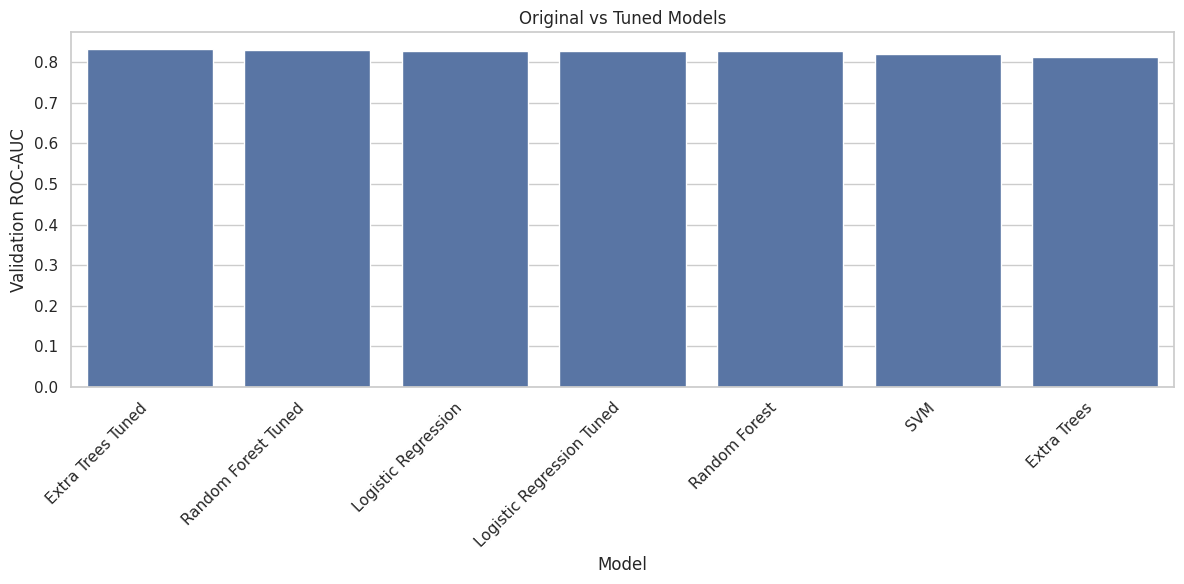

In [45]:

# Cell 44: Plot all models

plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_validation_results,
    x="Model",
    y="ROC_AUC"
)

plt.title("Original vs Tuned Models")
plt.ylabel("Validation ROC-AUC")
plt.xlabel("Model")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [46]:

# Cell 45: Create a list of all candidate models

all_models = {}

all_models.update(trained_models)
all_models.update(tuned_models)

print("Total candidate models:", len(all_models))

for name in all_models:
    print(name)


Total candidate models: 7
Logistic Regression
Random Forest
Extra Trees
SVM
Logistic Regression Tuned
Random Forest Tuned
Extra Trees Tuned


In [47]:

# Cell 46: Evaluate every candidate

final_model_results = []

for name, model in all_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    predictions = model.predict(X_val)

    final_model_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "F1": f1_score(
            y_val, predictions,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_val, probabilities
        ),

        "PR_AUC": average_precision_score(
            y_val, probabilities
        ),

        "Log_Loss": log_loss(
            y_val, probabilities
        )
    })

final_results_df = pd.DataFrame(
    final_model_results
)

final_results_df = final_results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(final_results_df)


,Model,Accuracy,F1,ROC_AUC,PR_AUC,Log_Loss
0,Extra Trees Tuned,0.786765,0.675200,0.831824,0.713671,0.518956
1,Random Forest Tuned,0.790966,0.677472,0.830851,0.710651,0.505897
2,Logistic Regression,0.769958,0.678414,0.828238,0.718520,0.508308
3,Logistic Regression Tuned,0.769958,0.678414,0.828238,0.718520,0.508308
4,Random Forest,0.787815,0.640569,0.826778,0.699818,0.479954
5,SVM,0.771008,0.667683,0.819274,0.694213,0.477807
6,Extra Trees,0.772059,0.581888,0.812028,0.679559,0.488686


In [48]:

# Cell 47: Select the five best models

top_5_models = final_results_df.head(5)

display(top_5_models)

print("\nTOP FIVE MODELS:")
for index, row in top_5_models.iterrows():

    print(
        f"{index + 1}. {row['Model']} "
        f"- ROC-AUC: {row['ROC_AUC']:.4f}"
    )


,Model,Accuracy,F1,ROC_AUC,PR_AUC,Log_Loss
0,Extra Trees Tuned,0.786765,0.675200,0.831824,0.713671,0.518956
1,Random Forest Tuned,0.790966,0.677472,0.830851,0.710651,0.505897
2,Logistic Regression,0.769958,0.678414,0.828238,0.718520,0.508308
3,Logistic Regression Tuned,0.769958,0.678414,0.828238,0.718520,0.508308
4,Random Forest,0.787815,0.640569,0.826778,0.699818,0.479954



TOP FIVE MODELS:
1. Extra Trees Tuned - ROC-AUC: 0.8318
2. Random Forest Tuned - ROC-AUC: 0.8309
3. Logistic Regression - ROC-AUC: 0.8282
4. Logistic Regression Tuned - ROC-AUC: 0.8282
5. Random Forest - ROC-AUC: 0.8268


In [49]:

# Cell 48: Fit top five models on full training data

final_trained_models = {}

for name in top_5_models["Model"]:

    model = all_models[name]

    model.fit(X, y)

    final_trained_models[name] = model

    print(name, "trained successfully!")


Extra Trees Tuned trained successfully!
Random Forest Tuned trained successfully!
Logistic Regression trained successfully!
Logistic Regression Tuned trained successfully!
Random Forest trained successfully!


In [50]:

# Cell 49: Generate test predictions

test_predictions = {}

test_probabilities = {}

for name, model in final_trained_models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    test_predictions[name] = predictions

    test_probabilities[name] = probabilities

    print(
        name,
        "Predictions generated:",
        len(predictions)
    )


Extra Trees Tuned Predictions generated: 4749
Random Forest Tuned Predictions generated: 4749
Logistic Regression Predictions generated: 4749
Logistic Regression Tuned Predictions generated: 4749
Random Forest Predictions generated: 4749


In [52]:

# Cell 50: Examine predicted classes

for name, predictions in test_predictions.items():

    print("\nModel:", name)

    print(
        pd.Series(predictions)
        .value_counts()
        .sort_index()
    )

    print(
        "Vaccinated percentage:",
        round(np.mean(predictions) * 100, 2),
        "%"
    )



Model: Extra Trees Tuned
0    3143
1    1606
Name: count, dtype: int64
Vaccinated percentage: 33.82 %

Model: Random Forest Tuned
0    3076
1    1673
Name: count, dtype: int64
Vaccinated percentage: 35.23 %

Model: Logistic Regression
0    2856
1    1893
Name: count, dtype: int64
Vaccinated percentage: 39.86 %

Model: Logistic Regression Tuned
0    2856
1    1893
Name: count, dtype: int64
Vaccinated percentage: 39.86 %

Model: Random Forest
0    3378
1    1371
Name: count, dtype: int64
Vaccinated percentage: 28.87 %


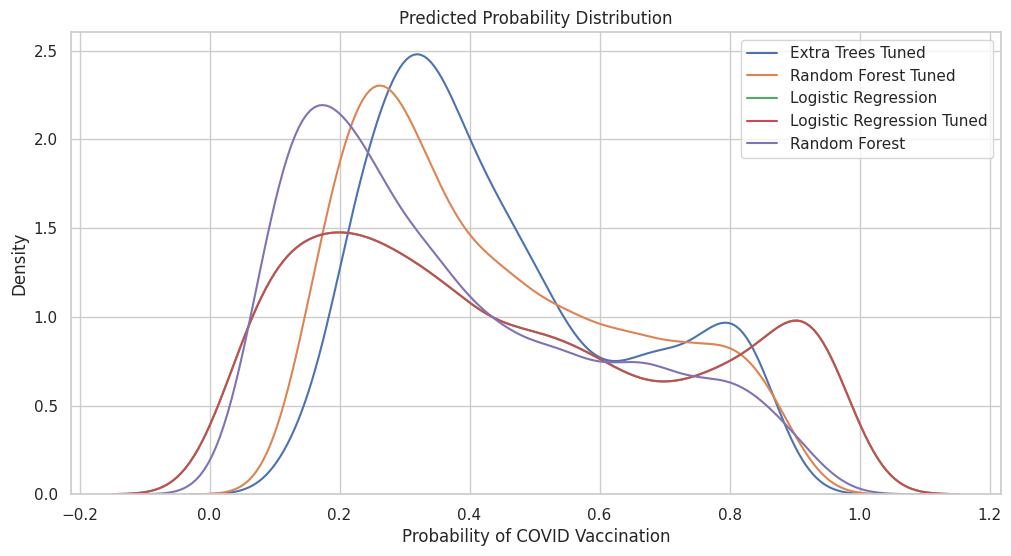

In [53]:

# Cell 51: Probability distributions

plt.figure(figsize=(12, 6))

for name, probabilities in test_probabilities.items():

    sns.kdeplot(
        probabilities,
        label=name
    )

plt.title("Predicted Probability Distribution")
plt.xlabel("Probability of COVID Vaccination")
plt.ylabel("Density")

plt.legend()
plt.show()


In [54]:

# Cell 52: Save five submission files

os.makedirs("submissions", exist_ok=True)

submission_files = []

for rank, name in enumerate(
    top_5_models["Model"],
    start=1
):

    predictions = test_predictions[name]

    submission = pd.DataFrame({

        "respondent_id": test_ids,

        "covid_vaccine": predictions

    })

    filename = f"submissions/submission_{rank}.csv"

    submission.to_csv(
        filename,
        index=False
    )

    submission_files.append(filename)

    print(
        f"Rank {rank}: {name} saved to {filename}"
    )


Rank 1: Extra Trees Tuned saved to submissions/submission_1.csv
Rank 2: Random Forest Tuned saved to submissions/submission_2.csv
Rank 3: Logistic Regression saved to submissions/submission_3.csv
Rank 4: Logistic Regression Tuned saved to submissions/submission_4.csv
Rank 5: Random Forest saved to submissions/submission_5.csv


In [55]:

# Cell 53: Save probability predictions

for rank, name in enumerate(
    top_5_models["Model"],
    start=1
):

    probability_submission = pd.DataFrame({

        "respondent_id": test_ids,

        "probability_covid_vaccine":
            test_probabilities[name]

    })

    filename = (
        f"submissions/probabilities_{rank}.csv"
    )

    probability_submission.to_csv(
        filename,
        index=False
    )

print("Probability files saved successfully!")


Probability files saved successfully!


In [56]:

# Cell 54: Export model evaluation results

final_results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

cv_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

tuning_df.to_csv(
    "hyperparameter_tuning_results.csv",
    index=False
)

print("Evaluation results exported!")


Evaluation results exported!


In [57]:

# Cell 55: Save trained models

for rank, (name, model) in enumerate(
    final_trained_models.items(),
    start=1
):

    filename = f"submissions/model_{rank}.pkl"

    joblib.dump(
        model,
        filename
    )

    print(name, "saved successfully!")


Extra Trees Tuned saved successfully!
Random Forest Tuned saved successfully!
Logistic Regression saved successfully!
Logistic Regression Tuned saved successfully!
Random Forest saved successfully!


In [58]:

# Cell 56: Verify submission files

for filename in submission_files:

    submission = pd.read_csv(filename)

    print("\nFile:", filename)

    print("Shape:", submission.shape)

    print("Missing values:")
    print(submission.isnull().sum())

    print("Duplicate IDs:")
    print(submission["respondent_id"].duplicated().sum())

    print("Prediction classes:")
    print(
        submission["covid_vaccine"].value_counts()
    )

    display(submission.head())



File: submissions/submission_1.csv
Shape: (4749, 2)
Missing values:
respondent_id    0
covid_vaccine    0
dtype: int64
Duplicate IDs:
0
Prediction classes:
covid_vaccine
0    3143
1    1606
Name: count, dtype: int64


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



File: submissions/submission_2.csv
Shape: (4749, 2)
Missing values:
respondent_id    0
covid_vaccine    0
dtype: int64
Duplicate IDs:
0
Prediction classes:
covid_vaccine
0    3076
1    1673
Name: count, dtype: int64


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



File: submissions/submission_3.csv
Shape: (4749, 2)
Missing values:
respondent_id    0
covid_vaccine    0
dtype: int64
Duplicate IDs:
0
Prediction classes:
covid_vaccine
0    2856
1    1893
Name: count, dtype: int64


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



File: submissions/submission_4.csv
Shape: (4749, 2)
Missing values:
respondent_id    0
covid_vaccine    0
dtype: int64
Duplicate IDs:
0
Prediction classes:
covid_vaccine
0    2856
1    1893
Name: count, dtype: int64


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



File: submissions/submission_5.csv
Shape: (4749, 2)
Missing values:
respondent_id    0
covid_vaccine    0
dtype: int64
Duplicate IDs:
0
Prediction classes:
covid_vaccine
0    3378
1    1371
Name: count, dtype: int64


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0


In [59]:
# Cell 57: View final test predictions summary

import pandas as pd
import numpy as np

# Create a consolidated DataFrame with test respondent IDs and predictions from all top models
predictions_summary_df = pd.DataFrame({
    'respondent_id': test_ids
})

for name in final_trained_models.keys():
    predictions_summary_df[f'{name}_Prediction'] = test_predictions[name]
    predictions_summary_df[f'{name}_Probability'] = test_probabilities[name]

print("=== Consolidated Test Predictions (First 10 Respondents) ===")
display(predictions_summary_df.head(10))

print("\n=== Descriptive Statistics of Prediction Probabilities ===")
display(predictions_summary_df.filter(like='Probability').describe())


=== Consolidated Test Predictions (First 10 Respondents) ===


,respondent_id,Extra Trees Tuned_Prediction,Extra Trees Tuned_Probability,Random Forest Tuned_Prediction,Random Forest Tuned_Probability,Logistic Regression_Prediction,Logistic Regression_Probability,Logistic Regression Tuned_Prediction,Logistic Regression Tuned_Probability,Random Forest_Prediction,Random Forest_Probability
0,4757,0,0.360333,0,0.321505,0,0.323851,0,0.323851,0,0.240081
1,4758,0,0.284329,0,0.289966,0,0.334092,0,0.334092,0,0.184989
2,4759,0,0.373685,0,0.320929,0,0.398240,0,0.398240,0,0.290283
3,4760,0,0.370679,0,0.405609,0,0.293257,0,0.293257,0,0.289269
4,4761,0,0.163579,0,0.133466,0,0.136454,0,0.136454,0,0.057724
5,4762,1,0.625162,1,0.712646,1,0.765321,1,0.765321,1,0.748525
6,4763,0,0.489984,1,0.509208,1,0.597748,1,0.597748,0,0.456919
7,4764,1,0.808484,1,0.819443,1,0.886761,1,0.886761,1,0.758362
8,4765,1,0.748186,1,0.808018,1,0.896979,1,0.896979,1,0.730731
9,4766,0,0.345731,0,0.368562,0,0.361267,0,0.361267,0,0.223258



=== Descriptive Statistics of Prediction Probabilities ===


,Extra Trees Tuned_Probability,Random Forest Tuned_Probability,Logistic Regression_Probability,Logistic Regression Tuned_Probability,Random Forest_Probability
count,4749.000000,4749.000000,4749.000000,4749.000000,4749.000000
mean,0.450826,0.437720,0.451012,0.451012,0.373592
std,0.197858,0.211259,0.284209,0.284209,0.235063
min,0.078334,0.084720,0.008564,0.008564,0.023798
25%,0.296826,0.262185,0.208247,0.208247,0.180021
50%,0.400435,0.388094,0.393014,0.393014,0.310127
75%,0.588184,0.600696,0.695455,0.695455,0.543365
max,0.931895,0.937158,0.995454,0.995454,0.975344


In [61]:
# Cell 58: Confirm and locate all generated result files

import os

# List of generated files we want to ensure are in the workspace
files_to_check = [
    "model_comparison_results.csv",
    "cross_validation_results.csv",
    "hyperparameter_tuning_results.csv",
    "submissions.zip"
]

print("=== File Status in Colab Workspace ===")
for f in files_to_check:
    if os.path.exists(f):
        print(f"✅ [FOUND] - Path: {os.path.abspath(f)} ({round(os.path.getsize(f)/1024, 2)} KB)")
    else:
        print(f"❌ [MISSING] - {f}")


=== File Status in Colab Workspace ===
✅ [FOUND] - Path: /content/model_comparison_results.csv (0.79 KB)
✅ [FOUND] - Path: /content/cross_validation_results.csv (0.41 KB)
✅ [FOUND] - Path: /content/hyperparameter_tuning_results.csv (0.47 KB)
✅ [FOUND] - Path: /content/submissions.zip (17416.95 KB)


In [62]:
# Cell 59: Save and export detailed predictions from the best model

import pandas as pd

best_model_name = "Extra Trees Tuned"

# Create a structured DataFrame containing the final outputs
predictions_df = pd.DataFrame({
    "respondent_id": test_ids,
    "predicted_class": test_predictions[best_model_name],
    "predicted_probability": test_probabilities[best_model_name]
})

# Save to a dedicated CSV file in the workspace
output_filename = "final_predictions_extra_trees.csv"
predictions_df.to_csv(output_filename, index=False)

print(f"Predictions from {best_model_name} successfully saved to {output_filename}!")
display(predictions_df.head(15))

Predictions from Extra Trees Tuned successfully saved to final_predictions_extra_trees.csv!


,respondent_id,predicted_class,predicted_probability
0,4757,0,0.360333
1,4758,0,0.284329
2,4759,0,0.373685
3,4760,0,0.370679
4,4761,0,0.163579
5,4762,1,0.625162
6,4763,0,0.489984
7,4764,1,0.808484
8,4765,1,0.748186
9,4766,0,0.345731


In [63]:
# Cell 60: Trigger download of final predictions

from google.colab import files

files.download('final_predictions_extra_trees.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>